<a href="https://colab.research.google.com/github/eishaiqbal767-cmyk/AI-TMBD-MOVIES-PROJECT/blob/main/Notebooks/TMBD_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Mounting Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


I mounted my Google Drive in Colab so the notebook can read and save files in my project folder. I did this because Colab's runtime is temporary, and anything saved only in the session disappears when it resets, while Drive keeps the raw data, processed data and reports safe. The output said Mounted at /content/drive, so the connection worked.



In [ ]:
import os
BASE = '/content/drive/MyDrive/AI_Project'
print(os.path.exists(BASE))
print(os.listdir(BASE))

True
['notebooks', 'data', 'reports', 'src']


I mounted my Google Drive in Colab so the notebook can read and save files in my project folder.

In [ ]:
import requests
from google.colab import userdata

TOKEN = userdata.get('TMDB_TOKEN')
BASE_URL = 'https://api.themoviedb.org/3'
HEADERS = {
    'Authorization': f'Bearer {TOKEN}',
    'accept': 'application/json'
}

params = {
    'primary_release_date.gte': '2016-01-01',
    'primary_release_date.lte': '2016-12-31',
    'sort_by': 'vote_count.desc',
    'page': 1
}
r = requests.get(f'{BASE_URL}/discover/movie', headers=HEADERS, params=params)
print('Status code:', r.status_code)
data = r.json()
print('Total results:', data['total_results'])
print('Total pages:', data['total_pages'])
print('Movies on this page:', len(data['results']))
print('First movie:', data['results'][0]['title'], '| id:', data['results'][0]['id'])

Status code: 200
Total results: 20001
Total pages: 1001
Movies on this page: 20
First movie: Deadpool | id: 293660


I made a first test request to the TMDB Discover endpoint to check that my API token works.

# TMDB Movie Data Analysis and Machine Learning

Programming for AI, semester project. Team: [Eisha Iqbal,25L-3003], [Ifrah noor, 25L-0025]. Instructor: Mahhek Tahir.

In this notebook I collect movie data from the TMDB API for the years 2016 to 2026, clean and explore it, and build regression models to predict a numerical target.

In [ ]:
import os, re, json, time, hashlib, random
from datetime import datetime
import numpy as np
import pandas as pd

ROLL_NUMBERS = ['25L-3003', '25L-0025']

SEED = 25

random.seed(SEED)
np.random.seed(SEED)

BASE = '/content/drive/MyDrive/AI_Project'
RAW_DIR = f'{BASE}/data/raw'
PROC_DIR = f'{BASE}/data/processed'
JSON_DIR = f'{RAW_DIR}/json'
os.makedirs(JSON_DIR, exist_ok=True)

START_YEAR, END_YEAR = 2016, 2026
MOVIES_PER_YEAR = 100
SORT_BY = 'vote_count.desc'

print('Roll numbers:', ROLL_NUMBERS)
print('SEED:', SEED)
print('Raw data folder:', RAW_DIR)
print('Years:', START_YEAR, 'to', END_YEAR, '| target per year:', MOVIES_PER_YEAR)
print('Sorting:', SORT_BY)

Roll numbers: ['25L-3003', '25L-0025']
SEED: 25
Raw data folder: /content/drive/MyDrive/AI_Project/data/raw
Years: 2016 to 2026 | target per year: 100
Sorting: vote_count.desc


I set up the project configuration in one cell, including my team's roll numbers, the SEED, the folder paths on Google Drive, the collection years and the sorting option. I used the last four digits of the lowest roll number as the SEED, as the instructions require, and I use it for every random state so that my results can be reproduced. I chose to sort the Discover results by vote count because movies with more votes usually have fuller records, including budget and revenue. The output confirms the settings and shows that the folders are ready.

In [ ]:
COLLECTION_START = datetime.now()
request_count = 0
id_records = []
seen_ids = set()

def api_get(path, params=None):
    global request_count
    for attempt in range(5):
        r = requests.get(f'{BASE_URL}{path}', headers=HEADERS, params=params, timeout=30)
        request_count += 1
        if r.status_code == 200:
            return r.json()
        if r.status_code == 429:
            time.sleep(2 * (attempt + 1))
            continue
        r.raise_for_status()
    raise RuntimeError('Too many failed attempts')

year_summary = []
for year in range(START_YEAR, END_YEAR + 1):
    collected, page, total_pages = 0, 1, None
    while collected < MOVIES_PER_YEAR:
        params = {
            'primary_release_date.gte': f'{year}-01-01',
            'primary_release_date.lte': f'{year}-12-31',
            'sort_by': SORT_BY,
            'vote_count.gte': 10,
            'include_adult': 'false',
            'language': 'en-US',
            'page': page
        }
        data = api_get('/discover/movie', params)
        total_pages = data['total_pages']
        for m in data['results']:
            if m['id'] in seen_ids:
                continue
            seen_ids.add(m['id'])
            id_records.append({'id': m['id'], 'title': m['title'],
                               'discover_year': year, 'discover_page': page})
            collected += 1
            if collected >= MOVIES_PER_YEAR:
                break
        if page >= total_pages:
            break
        page += 1
        time.sleep(0.05)
    year_summary.append({'year': year, 'collected': collected,'pages_used': page - 1
                         if collected >= MOVIES_PER_YEAR else page,
                         'api_total_pages': total_pages})

    print(year, '->', collected, 'movies')

ids_df = pd.DataFrame(id_records)
ids_df.to_csv(f'{RAW_DIR}/movie_ids.csv', index=False)
pd.DataFrame(year_summary).to_csv(f'{RAW_DIR}/discover_summary.csv', index=False)

print('\nUnique IDs:', ids_df['id'].nunique(), '| Requests so far:', request_count)
pd.DataFrame(year_summary)

2016 -> 100 movies
2017 -> 100 movies
2018 -> 100 movies
2019 -> 100 movies
2020 -> 100 movies
2021 -> 100 movies
2022 -> 100 movies
2023 -> 100 movies
2024 -> 100 movies
2025 -> 100 movies
2026 -> 100 movies

Unique IDs: 1100 | Requests so far: 55


,year,collected,pages_used,api_total_pages
0,2016,100,5,173
1,2017,100,5,185
2,2018,100,5,186
3,2019,100,5,184
4,2020,100,5,142
5,2021,100,5,148
6,2022,100,5,160
7,2023,100,5,153
8,2024,100,5,129
9,2025,100,5,102


The Discover step returned 1100 unique movie IDs, exactly 100 for each year from 2016 to 2026, with no duplicates. Each year needed 5 pages of 20 results, and the 11 years together used 55 requests.


In [ ]:
total = len(ids_df)
done_now, skipped = 0, 0

for i, movie_id in enumerate(ids_df['id'], start=1):
    path = f'{JSON_DIR}/{movie_id}.json'
    if os.path.exists(path):
        skipped += 1
        continue
    data = api_get(f'/movie/{movie_id}',
                   {'append_to_response': 'credits', 'language': 'en-US'})
    wrapper = {'collected_at': datetime.now().isoformat(timespec='seconds'),
               'data': data}
    with open(path, 'w', encoding='utf-8') as f:
        json.dump(wrapper, f)
    done_now += 1
    if i % 100 == 0:
        print(f'{i}/{total} processed')
    time.sleep(0.05)

COLLECTION_END = datetime.now()
files = [f for f in os.listdir(JSON_DIR) if f.endswith('.json')]
print('\nDownloaded now:', done_now, '| skipped (already saved):', skipped)
print('JSON files on Drive:', len(files))
print('Total requests (discover + details):', request_count)
print('Start:', COLLECTION_START.isoformat(timespec='seconds'))
print('End:  ', COLLECTION_END.isoformat(timespec='seconds'))

with open(f'{RAW_DIR}/collection_log.json', 'w') as f:
    json.dump({'roll_numbers': ROLL_NUMBERS,
               'start': COLLECTION_START.isoformat(timespec='seconds'),
               'end': COLLECTION_END.isoformat(timespec='seconds'),
               'requests': request_count}, f)

100/1100 processed
200/1100 processed
300/1100 processed
400/1100 processed
500/1100 processed
600/1100 processed
700/1100 processed
800/1100 processed
900/1100 processed
1000/1100 processed
1100/1100 processed

Downloaded now: 1100 | skipped (already saved): 0
JSON files on Drive: 1100
Total requests (discover + details): 1155
Start: 2026-11-21T19:51:32
End:   2026-11-21T20:07:55


For each of the 1100 movie IDs I called the Movie Details endpoint and asked for the credits in the same request, so I got budget, revenue, runtime, genres, languages, production companies, cast and crew without extra calls.

## RECOVERY CELL

In [1]:
from google.colab import drive, userdata
drive.mount('/content/drive')

import os, re, json, time, hashlib, random, requests
from datetime import datetime
import numpy as np
import pandas as pd

ROLL_NUMBERS = ['25L-3003', '25L-0025']
SEED = 25
random.seed(SEED)
np.random.seed(SEED)

BASE = '/content/drive/MyDrive/AI_Project'
RAW_DIR = f'{BASE}/data/raw'
PROC_DIR = f'{BASE}/data/processed'
JSON_DIR = f'{RAW_DIR}/json'

START_YEAR, END_YEAR = 2016, 2026
MOVIES_PER_YEAR = 100
SORT_BY = 'vote_count.desc'

try:
    TOKEN = userdata.get('TMDB_TOKEN')
except Exception:
    TOKEN = None   # not needed after data collection
BASE_URL = 'https://api.themoviedb.org/3'
HEADERS = {'Authorization': f'Bearer {TOKEN}', 'accept': 'application/json'}

ids_df = pd.read_csv(f'{RAW_DIR}/movie_ids.csv')
RAW_CSV = f'{RAW_DIR}/tmdb_raw.csv'
raw_df = pd.read_csv(RAW_CSV)
print('raw_df reloaded:', raw_df.shape)
print('IDs reloaded:', len(ids_df))
print('JSON files on Drive:', len([f for f in os.listdir(JSON_DIR) if f.endswith('.json')]))
df_model = pd.read_csv(f'{PROC_DIR}/tmdb_zeros_as_missing.csv')

Mounted at /content/drive
raw_df reloaded: (1100, 28)
IDs reloaded: 1100
JSON files on Drive: 1100


The Colab session restarted, so the variables in memory were lost. I remounted Google Drive, restored my settings, and reloaded the list of movie IDs from the file I had saved earlier.

SECTION 5C RECOVERY

In [2]:
from sklearn.impute import SimpleImputer

df_model = pd.read_csv(f'{PROC_DIR}/tmdb_zeros_as_missing.csv')
work = pd.read_csv(f'{PROC_DIR}/tmdb_working_5pct_missing.csv')

num_cols = ['runtime', 'cast_size', 'crew_size', 'budget']
imputed = work.copy()
imputed[num_cols] = SimpleImputer(strategy='median').fit_transform(imputed[num_cols])
imputed[['original_language']] = SimpleImputer(strategy='most_frequent').fit_transform(imputed[['original_language']])
imputed[['genres', 'production_countries']] = imputed[['genres', 'production_countries']].fillna('Unknown')

print('df_model:', df_model.shape, '| work:', work.shape, '| imputed:', imputed.shape)
print('Missing in imputed columns:', imputed[num_cols + ['original_language', 'genres', 'production_countries']].isnull().sum().sum())

df_model: (899, 28) | work: (899, 28) | imputed: (899, 28)
Missing in imputed columns: 0


Colab restarts clear the variables in memory, so this cell reloads the datasets that I saved to Drive during the cleaning section and rebuilds the imputed working copy from the saved file with the same imputation rules. It lets me continue from the encoding step without repeating the earlier cells. The output confirms that all three datasets have 899 rows and 28 columns and that no missing values remain in the imputed columns.

## SECTION 6 RECOVERY

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

eda = df_model.copy()
eda['release_date'] = pd.to_datetime(eda['release_date'])
eda['release_year'] = eda['release_date'].dt.year
eda['in_collection'] = eda['collection_name'].notna().map({True: 'In a collection', False: 'Standalone'})
eda['language_group'] = np.where(eda['original_language'] == 'en', 'English', 'Other')

print('eda rebuilt:', eda.shape)

eda rebuilt: (899, 31)


This cell rebuilds the table that I use for the exploratory analysis from the dataset saved on Drive, together with the release year and the collection and language groups. I added it so that I can continue from here after a restart without running all the earlier cells again. The output confirms that the table has 899 rows.

## SECTION 8 RECOVERY CELL

In [ ]:
treated = pd.read_csv(f'{PROC_DIR}/tmdb_invalid_removed.csv')
capped = pd.read_csv(f'{PROC_DIR}/tmdb_after_outlier_treatment.csv')
print('treated:', treated.shape, '| capped:', capped.shape)

treated: (898, 31) | capped: (898, 31)


This cell reloads the two datasets that I saved at the end of the outlier section, the one without the invalid movie and the one with the capped values, so that I can continue from here after a restart. The output shows that both tables have 898 rows and 31 columns, the same as before the restart.

## Section 9 and 10 Recovery

In [4]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, cross_val_score

fe = pd.read_csv(f'{PROC_DIR}/tmdb_features_final.csv')
X_all, y_all = fe.drop(columns='revenue'), fe['revenue']
revenue_bins = pd.qcut(y_all, q=5, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=SEED, stratify=revenue_bins)

class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, k=1.5):
        self.k = k
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.array(X.columns)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        self.lower_ = (q1 - self.k * (q3 - q1)).values
        self.upper_ = (q3 + self.k * (q3 - q1)).values
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(lower=self.lower_, upper=self.upper_, axis=1)
    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

other_num = ['release_year', 'release_month', 'release_weekday',
             'n_genres', 'n_companies', 'n_countries', 'n_spoken_languages']
binary_cols = ['is_part_of_collection', 'is_summer_release', 'is_holiday_release',
               'lang_en', 'budget_missing'] + [c for c in X_all.columns if c.startswith('genre_')]

preprocessor = ColumnTransformer([
    ('budget', Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('sqrt', FunctionTransformer(np.sqrt, feature_names_out='one-to-one')),
                         ('scale', StandardScaler())]), ['budget']),
    ('cast_crew', Pipeline([('cap', IQRCapper()),
                            ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                            ('scale', StandardScaler())]), ['cast_size', 'crew_size']),
    ('runtime', Pipeline([('cap', IQRCapper()), ('scale', StandardScaler())]), ['runtime']),
    ('other_num', StandardScaler(), other_num),
    ('binary', 'passthrough', binary_cols),
], verbose_feature_names_out=False).set_output(transform='pandas')

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)
y_train_log = np.log1p(y_train)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)

final_features = ['budget', 'is_part_of_collection', 'budget_missing', 'genre_Animation',
                  'crew_size', 'n_countries', 'n_genres', 'release_weekday',
                  'release_year', 'runtime']

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Median revenue train / test (M):', round(y_train.median() / 1e6, 1), '/', round(y_test.median() / 1e6, 1))
print('Final features:', len(final_features))

Train: (700, 33) | Test: (176, 33)
Median revenue train / test (M): 111.8 / 105.0
Final features: 10


This cell restores the work of Sections 9 and 10 after a Colab restart. It reloads the saved feature table, repeats the same stratified train test split with my team's seed, rebuilds the preprocessing pipeline fitted on the training data, and sets the 10 final features chosen in the feature selection section. The output confirms that the training and test sets have the same sizes and the same median revenues as the original split, so the results that follow are not affected by the restart.

## SECTION 11 AND 12 RECOVERY

In [5]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.model_selection import cross_validate
from sklearn.preprocessing import PowerTransformer

class ColumnSelector(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.columns]
    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns)

def make_model(reg):
    return Pipeline([
        ('prep', clone(preprocessor)),
        ('select', ColumnSelector(final_features)),
        ('model', TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1)),
    ]).set_output(transform='pandas')

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE_M': mean_absolute_error(y_true, y_pred) / 1e6, 'MSE': mse,
            'RMSE_M': np.sqrt(mse) / 1e6, 'R2': r2_score(y_true, y_pred)}

def log_r2(y_true, y_pred):
    return r2_score(np.log1p(y_true), np.log1p(np.clip(y_pred, 0, None)))

scoring = {'R2': 'r2', 'MAE': 'neg_mean_absolute_error',
           'RMSE': 'neg_root_mean_squared_error', 'R2_log': make_scorer(log_r2)}

def to_millions(X):
    return X / 1e6

def from_millions(X):
    return X * 1e6

gb_params = {'subsample': 0.6, 'n_estimators': 200, 'min_samples_leaf': 10,
             'max_depth': 2, 'learning_rate': 0.03}

models = {
    'Ridge': make_model(Ridge(alpha=1.0)),
    'Random Forest': make_model(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    'Gradient Boosting': make_model(GradientBoostingRegressor(random_state=SEED)),
}
gb_tuned = make_model(GradientBoostingRegressor(random_state=SEED, **gb_params))

rows = []
for name, m in list(models.items()) + [('Tuned GB', gb_tuned)]:
    m.fit(X_train, y_train)
    rows.append({'model': name, 'test R2': round(metrics(y_test, m.predict(X_test))['R2'], 3)})
final_model = gb_tuned
display(pd.DataFrame(rows).set_index('model'))

,test R2
model,
Ridge,0.554
Random Forest,0.455
Gradient Boosting,0.515
Tuned GB,0.462


## SECTION 14 RECOVERY  

In [10]:
def yj_target():
    return Pipeline([('millions', FunctionTransformer(to_millions, inverse_func=from_millions)),
                     ('yj', PowerTransformer(method='yeo-johnson'))])

yj_prep = ColumnTransformer([
    ('budget', Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('millions', FunctionTransformer(to_millions, feature_names_out='one-to-one')),
                         ('yj', PowerTransformer(method='yeo-johnson'))]), ['budget']),
    ('cast_crew', Pipeline([('cap', IQRCapper()),
                            ('yj', PowerTransformer(method='yeo-johnson'))]), ['cast_size', 'crew_size']),
    ('runtime', Pipeline([('cap', IQRCapper()), ('scale', StandardScaler())]), ['runtime']),
    ('other_num', StandardScaler(), other_num),
    ('binary', 'passthrough', binary_cols),
], verbose_feature_names_out=False).set_output(transform='pandas')

def build(reg, prep, target):
    if target == 'log':
        model = TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1)
    else:
        model = TransformedTargetRegressor(regressor=reg, transformer=yj_target())
    return Pipeline([('prep', clone(prep)), ('select', ColumnSelector(final_features)),
                     ('model', model)]).set_output(transform='pandas')

yj_models = {
    'Ridge | YJ features, log target': build(Ridge(alpha=1.0), yj_prep, 'log'),
    'Ridge | YJ features, YJ target': build(Ridge(alpha=1.0), yj_prep, 'yj'),
    'Tuned GB | YJ features, YJ target': build(GradientBoostingRegressor(random_state=SEED, **gb_params), yj_prep, 'yj'),
}
final_model = yj_models['Ridge | YJ features, YJ target']
print('Yeo-Johnson models restored:', list(yj_models))




Yeo-Johnson models restored: ['Ridge | YJ features, log target', 'Ridge | YJ features, YJ target', 'Tuned GB | YJ features, YJ target']


This cell restores the Yeo-Johnson preprocessing and the three models built with it in the advanced techniques section after a Colab restart, and sets the final model again. It only defines the models and does not train them, so it does not change any earlier results.



In [6]:
def names(items, key='name'):
    if not items:
        return None
    return '|'.join(str(x[key]) for x in items if x.get(key))

rows = []
for movie_id, disc_year in zip(ids_df['id'], ids_df['discover_year']):
    with open(f'{JSON_DIR}/{movie_id}.json', encoding='utf-8') as f:
        w = json.load(f)
    d, credits = w['data'], w['data'].get('credits', {})
    crew, cast = credits.get('crew', []), credits.get('cast', [])
    directors = [c['name'] for c in crew if c.get('job') == 'Director']
    coll = d.get('belongs_to_collection')
    rows.append({
        'id': d['id'],
        'title': d.get('title'),
        'original_title': d.get('original_title'),
        'release_date': d.get('release_date'),
        'discover_year': disc_year,
        'status': d.get('status'),
        'original_language': d.get('original_language'),
        'runtime': d.get('runtime'),
        'budget': d.get('budget'),
        'revenue': d.get('revenue'),
        'popularity': d.get('popularity'),
        'vote_average': d.get('vote_average'),
        'vote_count': d.get('vote_count'),
        'adult': d.get('adult'),
        'video': d.get('video'),
        'genres': names(d.get('genres')),
        'production_companies': names(d.get('production_companies')),
        'production_countries': names(d.get('production_countries')),
        'spoken_languages': names(d.get('spoken_languages'), 'english_name'),
        'collection_name': coll['name'] if coll else None,
        'director': directors[0] if directors else None,
        'top_cast': '|'.join(c['name'] for c in cast[:3]) or None,
        'cast_size': len(cast),
        'crew_size': len(crew),
        'tagline': d.get('tagline') or None,
        'overview': d.get('overview') or None,
        'imdb_id': d.get('imdb_id'),
        'collected_at': w['collected_at'],
    })

raw_df = pd.DataFrame(rows)
RAW_CSV = f'{RAW_DIR}/tmdb_raw.csv'
raw_df.to_csv(RAW_CSV, index=False, encoding='utf-8')

print('Rows:', raw_df.shape[0], '| Columns:', raw_df.shape[1])
print('Duplicate IDs:', raw_df['id'].duplicated().sum())
raw_df.head()

Rows: 1100 | Columns: 28
Duplicate IDs: 0


,id,title,original_title,release_date,discover_year,status,original_language,runtime,budget,revenue,...,spoken_languages,collection_name,director,top_cast,cast_size,crew_size,tagline,overview,imdb_id,collected_at
0,293660,Deadpool,Deadpool,2016-02-09,2016,Released,en,108,58000000,782837347,...,English,Deadpool Collection,Tim Miller,Ryan Reynolds|Morena Baccarin|Ed Skrein,52,489,Feel the love.,The origin story of former Special Forces oper...,tt1431045,2026-11-21T19:53:17
1,271110,Captain America: Civil War,Captain America: Civil War,2016-04-27,2016,Released,en,147,250000000,1155046416,...,Romanian|English|German|Russian,Captain America Collection,Joe Russo,Chris Evans|Robert Downey Jr.|Scarlett Johansson,104,296,United we stand. Divided we fall.,"Following the events of Age of Ultron, the col...",tt3498820,2026-11-21T19:53:17
2,284052,Doctor Strange,Doctor Strange,2016-10-25,2016,Released,en,115,180000000,676343174,...,English,Doctor Strange Collection,Scott Derrickson,Benedict Cumberbatch|Chiwetel Ejiofor|Rachel M...,44,253,The impossibilities are endless.,"After his career is destroyed, a brilliant but...",tt1211837,2026-11-21T19:53:18
3,297761,Suicide Squad,Suicide Squad,2016-08-03,2016,Released,en,122,175000000,749200054,...,English|Japanese|Spanish,Suicide Squad Collection,David Ayer,Will Smith|Jared Leto|Margot Robbie,106,194,Worst. Heroes. Ever.,"From DC Comics comes the Suicide Squad, an ant...",tt1386697,2026-11-21T19:53:19
4,329865,Arrival,Arrival,2016-11-10,2016,Released,en,116,47000000,203388186,...,Mandarin|English|Russian,None,Denis Villeneuve,Amy Adams|Jeremy Renner|Forest Whitaker,72,487,Why are they here?,Taking place after alien crafts land around th...,tt2543164,2026-11-21T19:53:20


I read the 1100 saved JSON files and combined them into a single table with one movie per row, then saved it as tmdb_raw.csv on Google Drive. I chose attributes from several groups: numbers such as budget, revenue, runtime and vote count, categories such as language, status and genre, dates such as the release date, and true or false values such as adult and video. Fields that hold several values, for example genres and production companies, were joined into one text value separated by a vertical bar so I can split them later during cleaning. I also took the director and the three top billed actors from the credits, and I kept a collected_at timestamp in every row. I did not change any values in this step, so zero budgets and zero revenues are still there and I will report them in the data cleaning section. The output shows 1100 rows and no repeated IDs.

In [7]:
log = {
    'roll_numbers': ROLL_NUMBERS,
    'start': '2026-11-21T19:51:32',
    'end': '2026-11-21T20:58:43',
    'requests': 1210,
    'note': ('First full collection 19:51-20:08: 55 discover + 1100 detail requests (1155). '
             'The discover step was rerun at 20:58 (55 requests) to fix a summary column; '
             'the 1100 saved detail files were reused, not downloaded again.')
}
with open(f'{RAW_DIR}/collection_log.json', 'w') as f:
    json.dump(log, f)
print(log)

{'roll_numbers': ['25L-3003', '25L-0025'], 'start': '2026-11-21T19:51:32', 'end': '2026-11-21T20:58:43', 'requests': 1210, 'note': 'First full collection 19:51-20:08: 55 discover + 1100 detail requests (1155). The discover step was rerun at 20:58 (55 requests) to fix a summary column; the 1100 saved detail files were reused, not downloaded again.'}


I corrected the saved collection log file so that it matches what really happened during the collection. When I reran the Discover step to fix a page count in my summary table, the log file was overwritten with the new start time and a request count of only 55. I restored the real values: the collection started at 19:51 and the last rerun ended at 20:58, and the total was 1210 requests, which is 1155 from the first full run plus 55 from the Discover rerun.  The output shows the corrected values. The dataset itself was not changed, because the 1100 detail files had already been saved and were reused.

In [8]:
def sha256_of(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(8192), b''):
            h.update(chunk)
    return h.hexdigest()

with open(f'{RAW_DIR}/collection_log.json') as f:
    log = json.load(f)

fingerprint = sha256_of(RAW_CSV)

print('=== DATA COLLECTION LOG ===')
print('Team roll numbers      :', ', '.join(log['roll_numbers']))
print('Source                 : TMDB API', BASE_URL)
print('Endpoints used         : /discover/movie, /movie/{id}?append_to_response=credits')
print('Collection start       :', log['start'])
print('Collection end         :', log['end'])
print('Number of requests     :', log['requests'], '(55 + 1100 first run, 55 discover rerun)')
print('Note                   :', log['note'])
print('Rows collected         :', len(raw_df))
print('collected_at column    : present | earliest', raw_df['collected_at'].min(),
      '| latest', raw_df['collected_at'].max())
print('Raw file               :', RAW_CSV)
print('SHA-256 fingerprint    :', fingerprint)

with open(f'{RAW_DIR}/data_collection_log.txt', 'w') as f:
    f.write(f"Roll numbers: {log['roll_numbers']}\nStart: {log['start']}\nEnd: {log['end']}\n"
            f"Requests: {log['requests']}\nNote: {log['note']}\nRows: {len(raw_df)}\nSHA-256: {fingerprint}\n")

=== DATA COLLECTION LOG ===
Team roll numbers      : 25L-3003, 25L-0025
Source                 : TMDB API https://api.themoviedb.org/3
Endpoints used         : /discover/movie, /movie/{id}?append_to_response=credits
Collection start       : 2026-11-21T19:51:32
Collection end         : 2026-11-21T20:58:43
Number of requests     : 1210 (55 + 1100 first run, 55 discover rerun)
Note                   : First full collection 19:51-20:08: 55 discover + 1100 detail requests (1155). The discover step was rerun at 20:58 (55 requests) to fix a summary column; the 1100 saved detail files were reused, not downloaded again.
Rows collected         : 1100
collected_at column    : present | earliest 2026-11-21T19:53:17 | latest 2026-11-21T20:07:55
Raw file               : /content/drive/MyDrive/AI_Project/data/raw/tmdb_raw.csv
SHA-256 fingerprint    : 45903e104914bc20dc3352cf6914673c628396a9ecb1d7fd110cd92a167b5447


This cell is my data collection log. It records my team's roll numbers, the source and endpoints, the start and end time, the number of requests, the number of rows, the collected_at column and the SHA-256 fingerprint of the raw CSV file. The first full collection ran from 19:51 to about 20:08 and used 1155 requests. The Discover step was rerun once with 55 more requests, and the 1100 detail files I had already saved were reused, so the log records 1210 requests in total. The collected_at values in the rows still show the original collection time. The fingerprint is calculated from the raw CSV file itself, so it works as proof that the file I submit is the one my own collection produced. From now on I will not overwrite tmdb_raw.csv, and all cleaning will be done on copies.

## SECTION **3**: Dataset Construction and Feature Selection



In [ ]:
dictionary = pd.DataFrame([
    ('id', 'TMDB movie identifier', 'identifier', 'excluded'),
    ('title', 'Movie title in English', 'text', 'excluded'),
    ('original_title', 'Title in the original language', 'text', 'excluded'),
    ('release_date', 'Date of release (YYYY-MM-DD)', 'date', 'feature (year, month, weekday derived)'),
    ('discover_year', 'Year used in the Discover query', 'numeric', 'excluded (collection artefact)'),
    ('status', 'Release status', 'categorical', 'excluded (near constant)'),
    ('original_language', 'Original language code', 'categorical', 'feature'),
    ('runtime', 'Length in minutes (0 means unknown)', 'numeric', 'feature'),
    ('budget', 'Production budget in USD (0 means unknown)', 'numeric', 'feature'),
    ('revenue', 'Worldwide revenue in USD (0 means unknown)', 'numeric', 'TARGET'),
    ('popularity', 'TMDB popularity score at collection time', 'numeric', 'excluded from model (post-release)'),
    ('vote_average', 'Mean audience rating (0 to 10)', 'numeric', 'excluded from model (post-release)'),
    ('vote_count', 'Number of audience votes', 'numeric', 'excluded from model (post-release)'),
    ('adult', 'Adult content flag', 'boolean', 'excluded (near constant)'),
    ('video', 'Video release flag', 'boolean', 'excluded (near constant)'),
    ('genres', 'Genres, separated by |', 'multi-valued categorical', 'feature (multi-hot)'),
    ('production_companies', 'Companies, separated by |', 'multi-valued categorical', 'feature (count derived)'),
    ('production_countries', 'Countries, separated by |', 'multi-valued categorical', 'feature (count derived)'),
    ('spoken_languages', 'Languages, separated by |', 'multi-valued categorical', 'feature (count derived)'),
    ('collection_name', 'Franchise or collection name', 'categorical', 'feature (is_part_of_collection derived)'),
    ('director', 'First credited director', 'categorical', 'candidate feature (high cardinality)'),
    ('top_cast', 'Three top billed actors, separated by |', 'multi-valued categorical', 'candidate feature'),
    ('cast_size', 'Number of credited cast members', 'numeric', 'candidate feature'),
    ('crew_size', 'Number of credited crew members', 'numeric', 'candidate feature'),
    ('tagline', 'Marketing tagline', 'text', 'excluded (optional text technique)'),
    ('overview', 'Plot summary', 'text', 'excluded (optional text technique)'),
    ('imdb_id', 'IMDb identifier', 'identifier', 'excluded'),
    ('collected_at', 'Time the row was collected', 'date-time', 'excluded'),
], columns=['column', 'meaning', 'kind', 'role'])

dictionary['pandas_dtype'] = dictionary['column'].map(raw_df.dtypes.astype(str))
print('Columns documented:', len(dictionary), '| columns in dataset:', raw_df.shape[1])
dictionary

Columns documented: 28 | columns in dataset: 28


,column,meaning,kind,role,pandas_dtype
0,id,TMDB movie identifier,identifier,excluded,int64
1,title,Movie title in English,text,excluded,object
2,original_title,Title in the original language,text,excluded,object
3,release_date,Date of release (YYYY-MM-DD),date,"feature (year, month, weekday derived)",object
4,discover_year,Year used in the Discover query,numeric,excluded (collection artefact),int64
5,status,Release status,categorical,excluded (near constant),object
6,original_language,Original language code,categorical,feature,object
7,runtime,Length in minutes (0 means unknown),numeric,feature,int64
8,budget,Production budget in USD (0 means unknown),numeric,feature,int64
9,revenue,Worldwide revenue in USD (0 means unknown),numeric,TARGET,int64


I wrote a data dictionary that lists every column with its meaning, its kind (numeric, categorical, boolean, date or text), its pandas data type and the role it will play in the project. I chose revenue as the target because it is a numerical value that can be predicted with regression. I decided that the prediction is made before a movie is released, so audience statistics such as vote average, vote count and popularity cannot be used as inputs, since they only exist after people have watched the film and would leak information about the revenue. I will still use them in the exploratory analysis. Identifiers and titles are excluded so they are not treated as numerical features, and fields that are almost constant, such as adult, video and status, would not help a model. Budget, runtime, release date parts, language, genres, companies, countries, collection membership, the director and the credit counts remain as candidate inputs, and the final set will be decided during feature selection. A limitation of this choice is that a pre-release model will likely be less accurate than one that uses audience votes.


SECTION 4: Data Understanding and Description

In [ ]:
print('Rows:', raw_df.shape[0], '| Columns:', raw_df.shape[1])
print('Columns:', list(raw_df.columns))
display(raw_df.head())
display(raw_df.tail())




Rows: 1100 | Columns: 28
Columns: ['id', 'title', 'original_title', 'release_date', 'discover_year', 'status', 'original_language', 'runtime', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'adult', 'video', 'genres', 'production_companies', 'production_countries', 'spoken_languages', 'collection_name', 'director', 'top_cast', 'cast_size', 'crew_size', 'tagline', 'overview', 'imdb_id', 'collected_at']


,id,title,original_title,release_date,discover_year,status,original_language,runtime,budget,revenue,...,spoken_languages,collection_name,director,top_cast,cast_size,crew_size,tagline,overview,imdb_id,collected_at
0,293660,Deadpool,Deadpool,2016-02-09,2016,Released,en,108,58000000,782837347,...,English,Deadpool Collection,Tim Miller,Ryan Reynolds|Morena Baccarin|Ed Skrein,52,489,Feel the love.,The origin story of former Special Forces oper...,tt1431045,2026-11-21T19:53:17
1,271110,Captain America: Civil War,Captain America: Civil War,2016-04-27,2016,Released,en,147,250000000,1155046416,...,Romanian|English|German|Russian,Captain America Collection,Joe Russo,Chris Evans|Robert Downey Jr.|Scarlett Johansson,104,296,United we stand. Divided we fall.,"Following the events of Age of Ultron, the col...",tt3498820,2026-11-21T19:53:17
2,284052,Doctor Strange,Doctor Strange,2016-10-25,2016,Released,en,115,180000000,676343174,...,English,Doctor Strange Collection,Scott Derrickson,Benedict Cumberbatch|Chiwetel Ejiofor|Rachel M...,44,253,The impossibilities are endless.,"After his career is destroyed, a brilliant but...",tt1211837,2026-11-21T19:53:18
3,297761,Suicide Squad,Suicide Squad,2016-08-03,2016,Released,en,122,175000000,749200054,...,English|Japanese|Spanish,Suicide Squad Collection,David Ayer,Will Smith|Jared Leto|Margot Robbie,106,194,Worst. Heroes. Ever.,"From DC Comics comes the Suicide Squad, an ant...",tt1386697,2026-11-21T19:53:19
4,329865,Arrival,Arrival,2016-11-10,2016,Released,en,116,47000000,203388186,...,Mandarin|English|Russian,NaN,Denis Villeneuve,Amy Adams|Jeremy Renner|Forest Whitaker,72,487,Why are they here?,Taking place after alien crafts land around th...,tt2543164,2026-11-21T19:53:20


,id,title,original_title,release_date,discover_year,status,original_language,runtime,budget,revenue,...,spoken_languages,collection_name,director,top_cast,cast_size,crew_size,tagline,overview,imdb_id,collected_at
1095,1248832,Digger,Digger,2026-09-28,2026,Released,en,129,180000000,50850116,...,English|Spanish|French|Mandarin,NaN,Alejandro G. Iñárritu,Tom Cruise|Riz Ahmed|John Goodman,89,121,A man. A plan. A meltdown.,The most powerful man in the world embarks on ...,tt31450459,2026-11-21T20:07:52
1096,949838,72 HOURS,72 HOURS,2026-07-20,2026,Released,en,105,0,0,...,English,NaN,Tim Story,Kevin Hart|Marcello Hernández|Mason Gooding,52,29,The night is young. He isn't.,"To save his career, a 40-year-old ad exec join...",tt36304003,2026-11-21T20:07:53
1097,1560520,Batman: Knightfall Part 1: Knightfall,Batman: Knightfall Part 1: Knightfall,2026-08-25,2026,Released,en,79,0,0,...,English|Spanish,Batman: Knightfall Collection,Jeff Wamester,Anson Mount|Michael Mando|Pablo Schreiber,22,143,NaN,"Arkham Asylum has been destroyed, and all its ...",tt32333324,2026-11-21T20:07:53
1098,1115544,Mike & Nick & Nick & Alice,Mike & Nick & Nick & Alice,2026-03-14,2026,Released,en,107,0,0,...,English,NaN,BenDavid Grabinski,James Marsden|Vince Vaughn|Eiza González,35,46,"A time-traveling, double-crossing, ass-kicking...",Two gangsters and the woman they love try to s...,tt27552099,2026-11-21T20:07:54
1099,1116201,Iron Lung,Iron Lung,2026-01-30,2026,Released,en,125,3000000,51226173,...,English,NaN,Mark Fischbach,Mark Fischbach|Caroline Kaplan|Troy Baker,23,159,This is not an expedition. It's an execution.,In a post-apocalyptic future where an event kn...,tt27564844,2026-11-21T20:07:55


I displayed the first and last five records and checked the size and column names of the raw dataset. I did this to get a first feel for the data and to confirm that the table was built correctly.The first rows come from 2016 and the last rows from 2026, because the data was collected year by year. The columns match the data dictionary I wrote earlier.

In [ ]:
raw_df.info()
print()
print('Numeric   :', raw_df.select_dtypes('number').columns.tolist())
print('Boolean   :', raw_df.select_dtypes('bool').columns.tolist())
print('Text/categorical:', raw_df.select_dtypes('object').columns.tolist())
print('\nMemory usage (MB):', round(raw_df.memory_usage(deep=True).sum() / 1e6, 2))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    1100 non-null   int64  
 1   title                 1100 non-null   object 
 2   original_title        1100 non-null   object 
 3   release_date          1100 non-null   object 
 4   discover_year         1100 non-null   int64  
 5   status                1100 non-null   object 
 6   original_language     1100 non-null   object 
 7   runtime               1100 non-null   int64  
 8   budget                1100 non-null   int64  
 9   revenue               1100 non-null   int64  
 10  popularity            1100 non-null   float64
 11  vote_average          1100 non-null   float64
 12  vote_count            1100 non-null   int64  
 13  adult                 1100 non-null   bool   
 14  video                 1100 non-null   bool   
 15  genres               

I used info to check the data types and the number of non-null values in each column, and I grouped the columns into numeric, boolean and text types. I also measured how much memory the dataset uses. This matters because the date columns, release_date and collected_at, were read as plain text and will have to be converted to dates later. The multi-valued fields, such as genres, are text and will need splitting before encoding. The dataset is small, using about [X] MB, so memory is not a concern.

In [ ]:
display(raw_df.describe().T)
display(raw_df.describe(include='object').T)

,count,mean,std,min,25%,50%,75%,max
id,1100.0,6.478979e+05,3.185277e+05,14564.0000,4.018530e+05,5.652270e+05,8.412598e+05,1.698863e+06
discover_year,1100.0,2.021000e+03,3.163716e+00,2016.0000,2.018000e+03,2.021000e+03,2.024000e+03,2.026000e+03
runtime,1100.0,1.151191e+02,2.030853e+01,12.0000,1.020000e+02,1.120000e+02,1.260000e+02,2.420000e+02
budget,1100.0,6.165258e+07,7.476431e+07,0.0000,9.000000e+06,3.500000e+07,9.000000e+07,6.588000e+08
revenue,1100.0,1.882582e+08,3.210708e+08,0.0000,6.151455e+06,6.083273e+07,2.139270e+08,2.942661e+09
popularity,1100.0,1.214923e+01,2.710758e+01,0.0541,5.004025e+00,7.319800e+00,1.153540e+01,4.817218e+02
vote_average,1100.0,6.943792e+00,6.741157e-01,3.9760,6.484500e+00,6.937500e+00,7.393250e+00,9.093000e+00
vote_count,1100.0,4.633278e+03,4.394863e+03,490.0000,1.863500e+03,3.180500e+03,5.585000e+03,3.366000e+04
cast_size,1100.0,4.847091e+01,3.406892e+01,0.0000,2.900000e+01,4.100000e+01,6.000000e+01,3.940000e+02
crew_size,1100.0,1.470682e+02,1.077676e+02,1.0000,7.475000e+01,1.220000e+02,1.840000e+02,8.300000e+02


,count,unique,top,freq
title,1100,1096,Deep Water,2
original_title,1100,1096,Deep Water,2
release_date,1100,870,2021-11-24,5
status,1100,1,Released,1100
original_language,1100,16,en,1021
genres,1100,493,Drama,33
production_companies,1099,992,Pixar,14
production_countries,1098,176,United States of America,651
spoken_languages,1095,242,English,640
collection_name,392,256,The Fast and the Furious Collection,4


I generated descriptive statistics for the numeric columns and for the text columns. For the numeric ones I looked at the mean, spread, minimum and maximum, and for the text ones the number of unique values and the most common value. I noticed that the minimum of budget, revenue and runtime is 0, which in TMDB means the value is unknown and not a real zero, and the large gap between the mean and the maximum in budget and revenue suggests strong skewness. This will guide my cleaning and my treatment of skewness later.

In [ ]:
for col in ['original_language', 'status', 'adult', 'video', 'collection_name', 'director']:
    print(f'--- {col}: {raw_df[col].nunique()} unique values')
    print(raw_df[col].value_counts().head(8), '\n')

genre_counts = raw_df['genres'].dropna().str.split('|').explode().value_counts()
print('--- genres (multi-valued):', len(genre_counts), 'unique genres')
print(genre_counts)

--- original_language: 16 unique values
original_language
en    1021
ja      17
fr      14
es      13
ko       9
it       6
no       4
zh       3
Name: count, dtype: int64 

--- status: 1 unique values
status
Released    1100
Name: count, dtype: int64 

--- adult: 1 unique values
adult
False    1100
Name: count, dtype: int64 

--- video: 1 unique values
video
False    1100
Name: count, dtype: int64 

--- collection_name: 256 unique values
collection_name
The Fast and the Furious Collection            4
Spider-Man (MCU) Collection                    4
Deadpool Collection                            3
Fantastic Beasts Collection                    3
Hercule Poirot (Kenneth Branagh) Collection    3
John Wick Collection                           3
The Conjuring Collection                       3
The Purge Collection                           3
Name: count, dtype: int64 

--- director: 679 unique values
director
Guy Ritchie           9
Antoine Fuqua         6
Ridley Scott          6
Steven S

I counted the unique values and the most frequent values of the categorical columns, and I split the genres field to count each genre separately, since a movie can have several genres. I wanted to know which columns are suitable for one-hot encoding and which have too many categories. Language has a few dominant values, status, adult and video are almost constant, and director and collection name have many unique values. The genre counts show which genres are common and which are rare. This tells me that director needs a different treatment than simple one-hot encoding.

In [ ]:
missing = raw_df.isnull().sum().to_frame('missing_NaN')
missing['percent'] = (missing['missing_NaN'] / len(raw_df) * 100).round(2)
display(missing[missing['missing_NaN'] > 0])

zero_cols = ['budget', 'revenue', 'runtime']
zeros = pd.DataFrame({'zeros': [(raw_df[c] == 0).sum() for c in zero_cols]}, index=zero_cols)
zeros['percent'] = (zeros['zeros'] / len(raw_df) * 100).round(2)
display(zeros)

print('Duplicate rows:', raw_df.duplicated().sum())
print('Duplicate movie IDs:', raw_df['id'].duplicated().sum())

,missing_NaN,percent
production_companies,1,0.09
production_countries,2,0.18
spoken_languages,5,0.45
collection_name,708,64.36
top_cast,2,0.18
tagline,43,3.91
imdb_id,1,0.09


,zeros,percent
budget,160,14.55
revenue,201,18.27
runtime,0,0.00


Duplicate rows: 0
Duplicate movie IDs: 0


I checked every column for missing values and counted the zeros in budget, revenue and runtime, because TMDB stores unknown values of these fields as 0 and not as an empty cell. I also checked for duplicate rows and repeated movie IDs. The output shows which columns have real missing values, such as tagline or collection name, and how many movies have a zero budget, revenue or runtime. There are no duplicate rows or repeated IDs, which agrees with how I collected the data. I will treat the zeros as missing values in the cleaning section.

## Section 5:Data Cleaning and Preprocessing

### Section 5A:Missing Values

In [ ]:
from sklearn.impute import SimpleImputer

zero_cols = ['budget', 'revenue', 'runtime']
orig = raw_df.copy()
orig[zero_cols] = orig[zero_cols].replace(0, np.nan)

rep = orig.isnull().sum().to_frame('missing')
rep['percent'] = (rep['missing'] / len(orig) * 100).round(2)
display(rep[rep['missing'] > 0].sort_values('missing', ascending=False))

both = (orig['budget'].isnull() & orig['revenue'].isnull()).sum()
print('Movies missing both budget and revenue:', both)

,missing,percent
collection_name,708,64.36
revenue,201,18.27
budget,160,14.55
tagline,43,3.91
spoken_languages,5,0.45
top_cast,2,0.18
production_countries,2,0.18
production_companies,1,0.09
imdb_id,1,0.09


Movies missing both budget and revenue: 128


I reported the original missing values after treating the zeros in budget, revenue and runtime as missing, because TMDB uses 0 for an unknown value. I worked on a copy so that the raw dataset stays untouched. The table shows that revenue is missing in 201 movies, which is 18.27 percent, and budget in 160 movies, which is 14.55 percent, while runtime has none. Collection name is the most empty column, but that is because most movies are not part of a collection. A number of movies are missing both budget and revenue, and the output shows how many. These counts are the original condition of the data before I introduce any artificial missing values.

In [ ]:
df_model = orig[orig['revenue'].notna()].reset_index(drop=True)
print('Rows before:', len(orig), '| rows after removing missing revenue:', len(df_model))
print('Rows removed:', len(orig) - len(df_model))
print('Budget still missing among kept rows:', df_model['budget'].isnull().sum())

df_model.to_csv(f'{PROC_DIR}/tmdb_zeros_as_missing.csv', index=False)

Rows before: 1100 | rows after removing missing revenue: 899
Rows removed: 201
Budget still missing among kept rows: 32


I removed the movies whose revenue is missing, since a model cannot be trained or tested on a target that is not known, and I did not fill the target with an estimate. This reduced the dataset from 1100 to 899 movies. Budget is still missing for some of the movies that remain, and I will impute those values later, because budget is an input and not the target. I saved this dataset to Drive as the base for the rest of the cleaning.

In [ ]:
rng = np.random.RandomState(SEED)
work = df_model.copy()

num_missing_cols = ['runtime', 'cast_size', 'crew_size']
cat_missing_cols = ['original_language', 'genres', 'production_countries']
work[num_missing_cols] = work[num_missing_cols].astype('float64')

n_cells = int(round(0.05 * len(work)))
for c in num_missing_cols + cat_missing_cols:
    idx = rng.choice(work.index, size=n_cells, replace=False)
    work.loc[idx, c] = np.nan

assert work['revenue'].isnull().sum() == 0   # the target is untouched

compare = pd.DataFrame({
    'before_5pct': df_model[num_missing_cols + cat_missing_cols + ['budget']].isnull().sum(),
    'after_5pct': work[num_missing_cols + cat_missing_cols + ['budget']].isnull().sum()
})
display(compare)
work.to_csv(f'{PROC_DIR}/tmdb_working_5pct_missing.csv', index=False)

,before_5pct,after_5pct
runtime,0,45
cast_size,0,45
crew_size,0,45
original_language,0,45
genres,0,45
production_countries,0,45
budget,32,32


I made a separate working copy of the dataset and removed about 5 percent of the values at random from six input columns: runtime, cast size, crew size, original language, genres and production countries. I did this to practise missing data handling on a dataset where I know the original values. I used my team's seed for the random choice so that the result can be reproduced, and I did not touch the target column, which a check in the code confirms. The table compares the missing counts before and after, and each chosen column now has about 45 missing cells. Budget was not changed, because it already contains the missing values from the zeros. I saved this working copy to Drive as a separate file.

In [ ]:
num_cols = ['runtime', 'cast_size', 'crew_size', 'budget']
print('Mean vs median (why median):')
display(work[num_cols].agg(['mean', 'median']).T)

imputed = work.copy()
imputed[num_cols] = SimpleImputer(strategy='median').fit_transform(imputed[num_cols])
imputed[['original_language']] = SimpleImputer(strategy='most_frequent').fit_transform(imputed[['original_language']])
imputed[['genres', 'production_countries']] = imputed[['genres', 'production_countries']].fillna('Unknown')

cols = num_cols + ['original_language', 'genres', 'production_countries']
display(pd.DataFrame({'before_imputation': work[cols].isnull().sum(),
                      'after_imputation': imputed[cols].isnull().sum()}))

Mean vs median (why median):


,mean,median
runtime,1.163407e+02,113.0
cast_size,5.062178e+01,43.0
crew_size,1.578548e+02,134.5
budget,7.303698e+07,42000000.0


,before_imputation,after_imputation
runtime,45,0
cast_size,45,0
crew_size,45,0
budget,32,0
original_language,45,0
genres,45,0
production_countries,45,0


I filled the missing values according to the type and distribution of each column. For the numeric columns, runtime, cast size, crew size and budget, I used the median, because the means are pulled up by a few very large values, especially for budget and crew size, and the median is not affected by them. For original language I used the most frequent value, which is English, and for genres and production countries, which hold several values, I used a separate category called Unknown, because choosing the most common combination would invent information. The table shows that every selected column went from having missing values to having none.

### SECTION 5B:Duplicate Handling

In [ ]:
exact = df_model.duplicated().sum()
same_id = df_model['id'].duplicated().sum()
same_title_date = df_model.duplicated(subset=['title', 'release_date']).sum()
print('Exact duplicate rows:', exact)
print('Repeated movie IDs:', same_id)
print('Repeated title + release date:', same_title_date)

before = len(df_model)
df_model = df_model.drop_duplicates().reset_index(drop=True)
print('Rows removed:', before - len(df_model), '| rows now:', len(df_model))

display(df_model[df_model['title'].duplicated(keep=False)][['id', 'title', 'release_date']]
        .sort_values('title'))

Exact duplicate rows: 0
Repeated movie IDs: 0
Repeated title + release date: 0
Rows removed: 0 | rows now: 899


,id,title,release_date
276,483184,Dogman,2018-05-17
649,944401,Dogman,2023-09-27
13,277834,Moana,2016-10-13
870,1108427,Moana,2026-07-08


I looked for duplicate movies in three ways: exact duplicate rows, repeated movie IDs, and the same title with the same release date. I checked because a repeated movie would count twice in the training and test data and make the results look better than they are. I found no exact duplicates and no repeated IDs, so no rows were removed and the dataset still has 899 movies. A few titles appear twice, but the table shows that they are different movies with different IDs and release dates, so they are not duplicates and I keep them.

### SECTION 5C: Categorical Encoding

In [ ]:
enc = imputed.copy()

def n_items(s):
    return 0 if (pd.isna(s) or s == 'Unknown') else s.count('|') + 1

enc['language_group'] = np.where(enc['original_language'] == 'en', 'en', 'other')
lang_dummies = pd.get_dummies(enc['language_group'], prefix='lang', dtype=int)

genre_dummies = enc['genres'].str.get_dummies(sep='|').add_prefix('genre_')

enc['is_part_of_collection'] = enc['collection_name'].notna().astype(int)
enc['n_companies'] = enc['production_companies'].apply(n_items)
enc['n_countries'] = enc['production_countries'].apply(n_items)
enc['n_spoken_languages'] = enc['spoken_languages'].apply(n_items)

encoded = pd.concat([enc[['budget', 'runtime', 'cast_size', 'crew_size',
                          'is_part_of_collection', 'n_companies', 'n_countries',
                          'n_spoken_languages', 'revenue']],
                     lang_dummies, genre_dummies], axis=1)
print('Encoded shape:', encoded.shape)
print('Genre columns:', genre_dummies.shape[1])
display(encoded.head())

Encoded shape: (899, 29)
Genre columns: 18


,budget,runtime,cast_size,crew_size,is_part_of_collection,n_companies,n_countries,n_spoken_languages,revenue,lang_en,...,genre_History,genre_Horror,genre_Music,genre_Mystery,genre_Romance,genre_Science Fiction,genre_Thriller,genre_Unknown,genre_War,genre_Western
0,58000000.0,108.0,52.0,489.0,1,4,1,1,7.828373e+08,1,...,0,0,0,0,0,0,0,0,0,0
1,250000000.0,147.0,104.0,296.0,1,1,1,4,1.155046e+09,1,...,0,0,0,0,0,1,0,0,0,0
2,180000000.0,115.0,44.0,253.0,1,1,1,1,6.763432e+08,1,...,0,0,0,0,0,0,0,0,0,0
3,175000000.0,122.0,106.0,134.5,1,4,1,3,7.492001e+08,1,...,0,0,0,0,0,0,0,0,0,0
4,47000000.0,116.0,72.0,487.0,0,3,1,3,2.033882e+08,1,...,0,0,0,1,0,1,0,0,0,0


I encoded the categorical variables so that the models can use them. Original language had one dominant value, so I grouped it into English and other and applied one-hot encoding. Genres hold several values per movie, so I split them and created one column per genre with a 1 or 0, which is called multi-hot encoding. Collection name has too many different values to encode, so I replaced it with a flag showing whether the movie belongs to a collection, and I turned production companies, countries and spoken languages into counts. Director has 679 values and is left out of this step because one-hot encoding it would add hundreds of columns. The output shows the shape of the encoded table and the first rows.

### Section 5D: Numerical Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scale_cols = ['budget', 'runtime', 'cast_size', 'crew_size',
              'n_companies', 'n_countries', 'n_spoken_languages']

scaled = encoded.copy()
scaled[scale_cols] = StandardScaler().fit_transform(encoded[scale_cols])

print('BEFORE scaling')
display(encoded[scale_cols].describe().T[['mean', 'std', 'min', 'max']].round(2))
print('AFTER scaling')
display(scaled[scale_cols].describe().T[['mean', 'std', 'min', 'max']].round(2))

scaled.to_csv(f'{PROC_DIR}/tmdb_cleaned_preprocessed.csv', index=False)

BEFORE scaling


,mean,std,min,max
budget,71932215.18,76374165.01,7.0,658800000.0
runtime,116.17,19.40,57.0,215.0
cast_size,50.24,34.96,0.0,394.0
crew_size,156.69,109.11,12.0,830.0
n_companies,3.86,2.06,1.0,16.0
n_countries,1.49,0.97,0.0,10.0
n_spoken_languages,1.77,1.27,0.0,9.0


AFTER scaling


,mean,std,min,max
budget,0.0,1.0,-0.94,7.69
runtime,-0.0,1.0,-3.05,5.10
cast_size,-0.0,1.0,-1.44,9.84
crew_size,-0.0,1.0,-1.33,6.17
n_companies,0.0,1.0,-1.39,5.90
n_countries,0.0,1.0,-1.53,8.78
n_spoken_languages,-0.0,1.0,-1.40,5.71


I scaled the numeric input features with StandardScaler, which subtracts the mean and divides by the standard deviation so that every feature has a mean of about 0 and a standard deviation of about 1. I did this because budget is measured in millions while the other features are small numbers, and algorithms that depend on distances or coefficients, such as linear regression with regularization, would otherwise be dominated by the largest values. I did not scale the target, the 0 and 1 columns from encoding, or the collection flag, since they are already on a small scale and the target should keep its real units. The tables show that the means and standard deviations were very different before scaling and are now about 0 and 1. Scaling does not change the shape of a distribution, so the strong skewness of budget remains and I will deal with it in the skewness section. Tree based models do not need scaling, but I will use the same prepared data for all models and fit the scaler on the training data only in the final pipeline. I saved the result to Drive as the preprocessed dataset.

## SECTION 6: (EDA) Exploratory Data Analysis

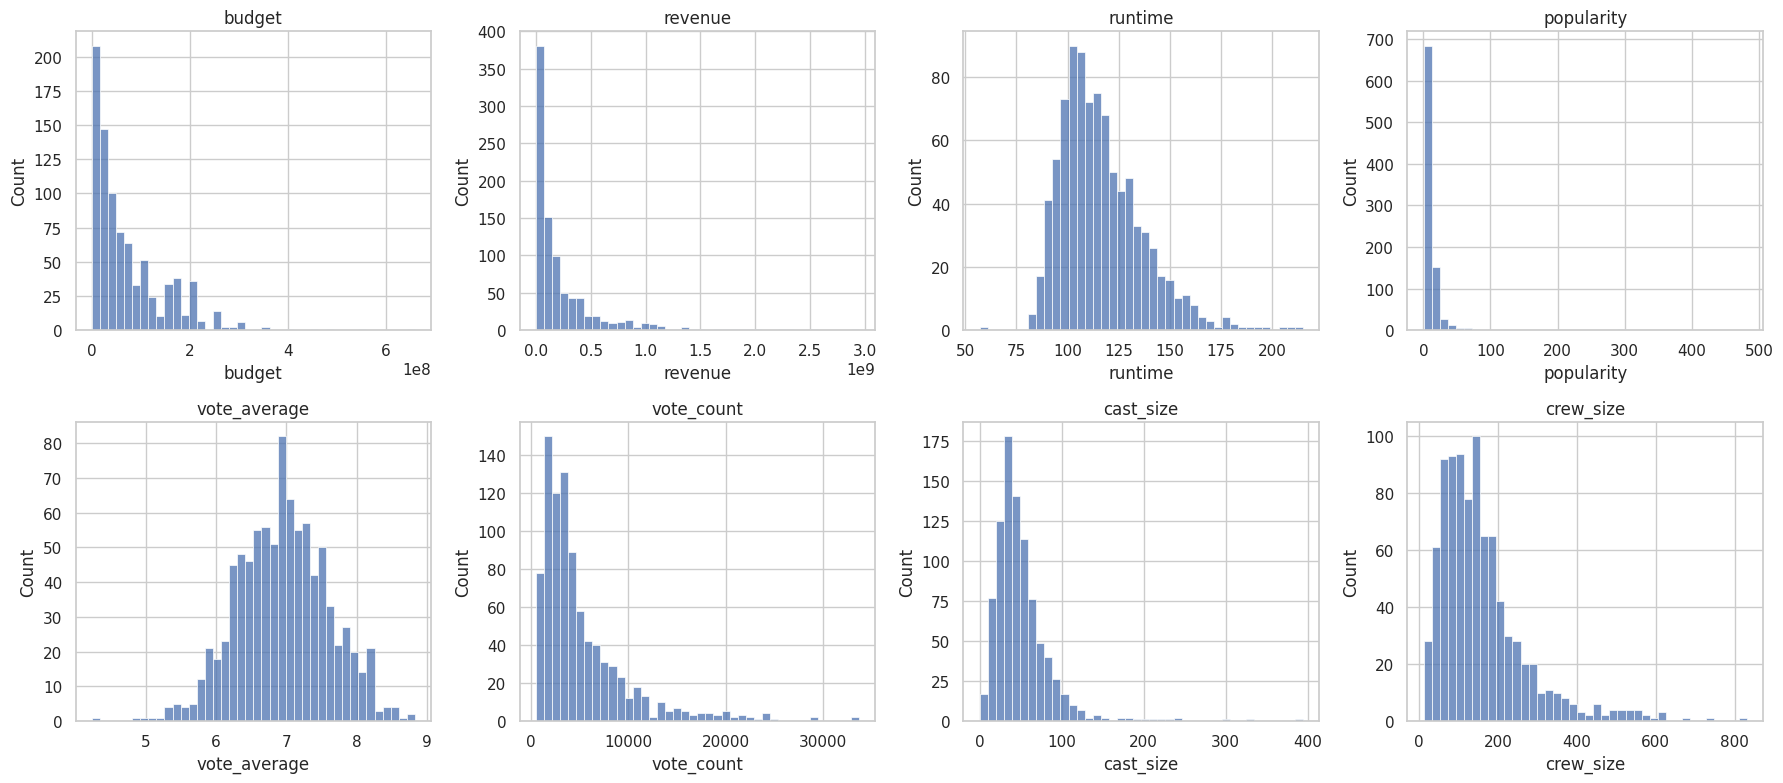

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

eda = df_model.copy()
eda['release_date'] = pd.to_datetime(eda['release_date'])
eda['release_year'] = eda['release_date'].dt.year
num_eda = ['budget', 'revenue', 'runtime', 'popularity',
           'vote_average', 'vote_count', 'cast_size', 'crew_size']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_eda):
    sns.histplot(eda[c].dropna(), bins=40, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

I plotted a histogram for each numeric variable to see how its values are distributed. I did this to find out which variables are symmetric and which are skewed, and to spot unusual values before modeling. Budget, revenue, vote count and cast size are strongly right skewed, with most movies at low or moderate values and a few very large values far to the right, such as revenues approaching 3 billion and vote counts above 30000. Budget also has a small group of movies around 150 to 200 million, where big studio productions cluster. Runtime is close to a bell shape centered between 100 and 125 minutes with a slight tail of long films, and vote average is also roughly bell shaped around 7. Popularity and crew size are right skewed as well. This tells me that the skewed variables will probably need a transformation, which I examine in the skewness section.

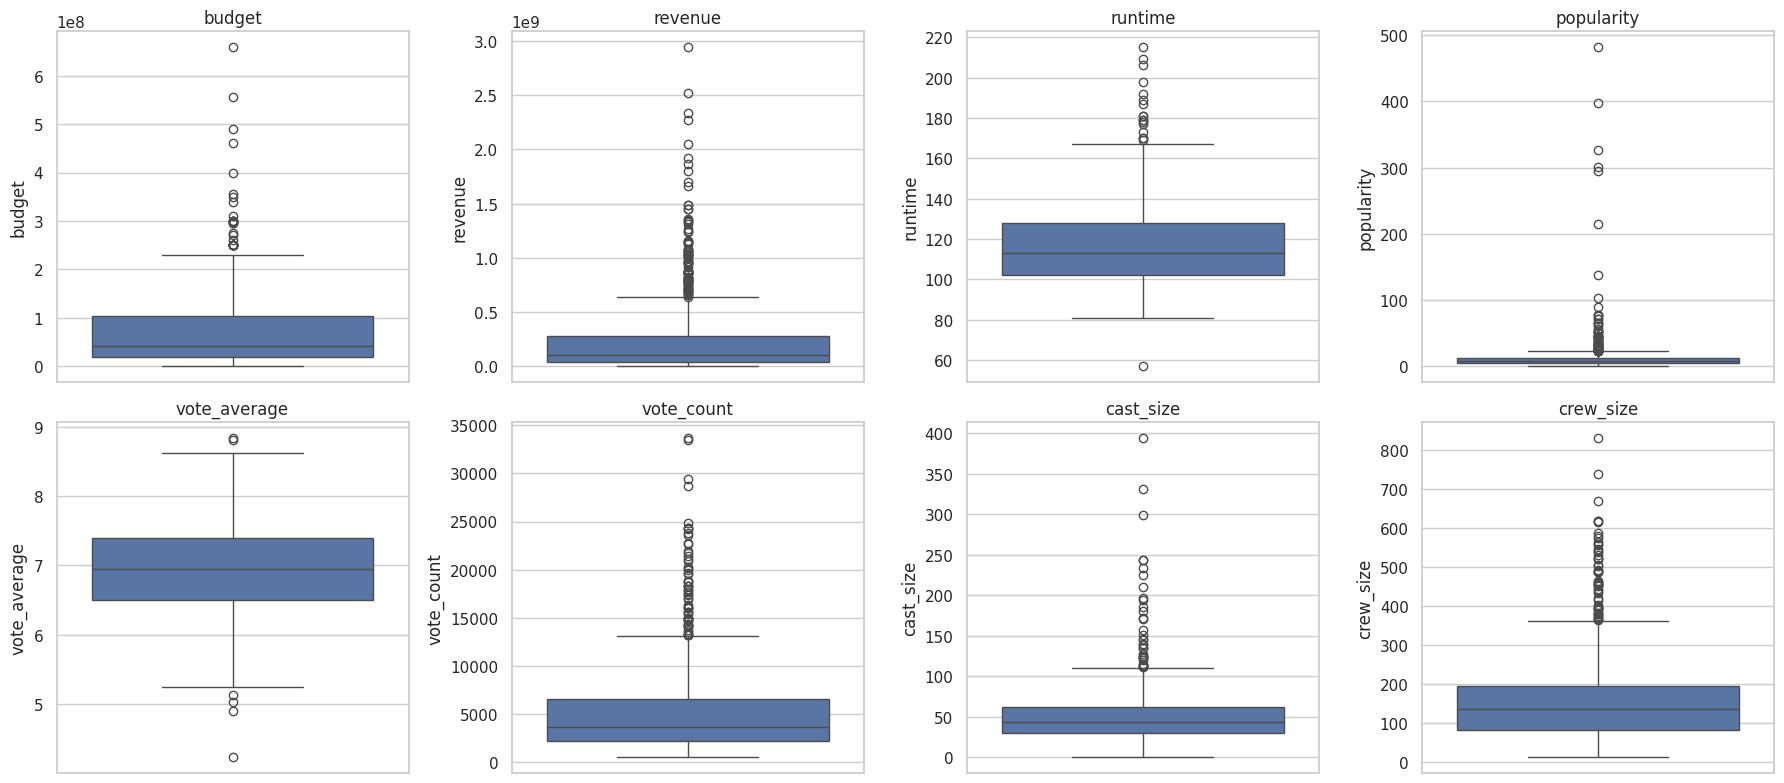

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_eda):
    sns.boxplot(y=eda[c].dropna(), ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

I drew a box plot for each numeric variable to see the median, the spread and the potential outliers, which are the points beyond the whiskers. I did this to see where extreme values occur before I analyze them formally with the IQR method. Budget, revenue, popularity, vote count, cast size and crew size have many points above the upper whisker. Revenue is the most extreme, with a median of about 110 million and outliers reaching almost 3 billion, and popularity is squeezed near zero with a few very high values. Runtime and vote average have outliers on both sides, such as a very short film of about 57 minutes, films longer than 170 minutes, and ratings below 5 or above 8.5. Most of these extreme values look like genuine observations, for example big blockbusters and very long epics, so I will not delete them automatically and I will investigate them in the outlier section.



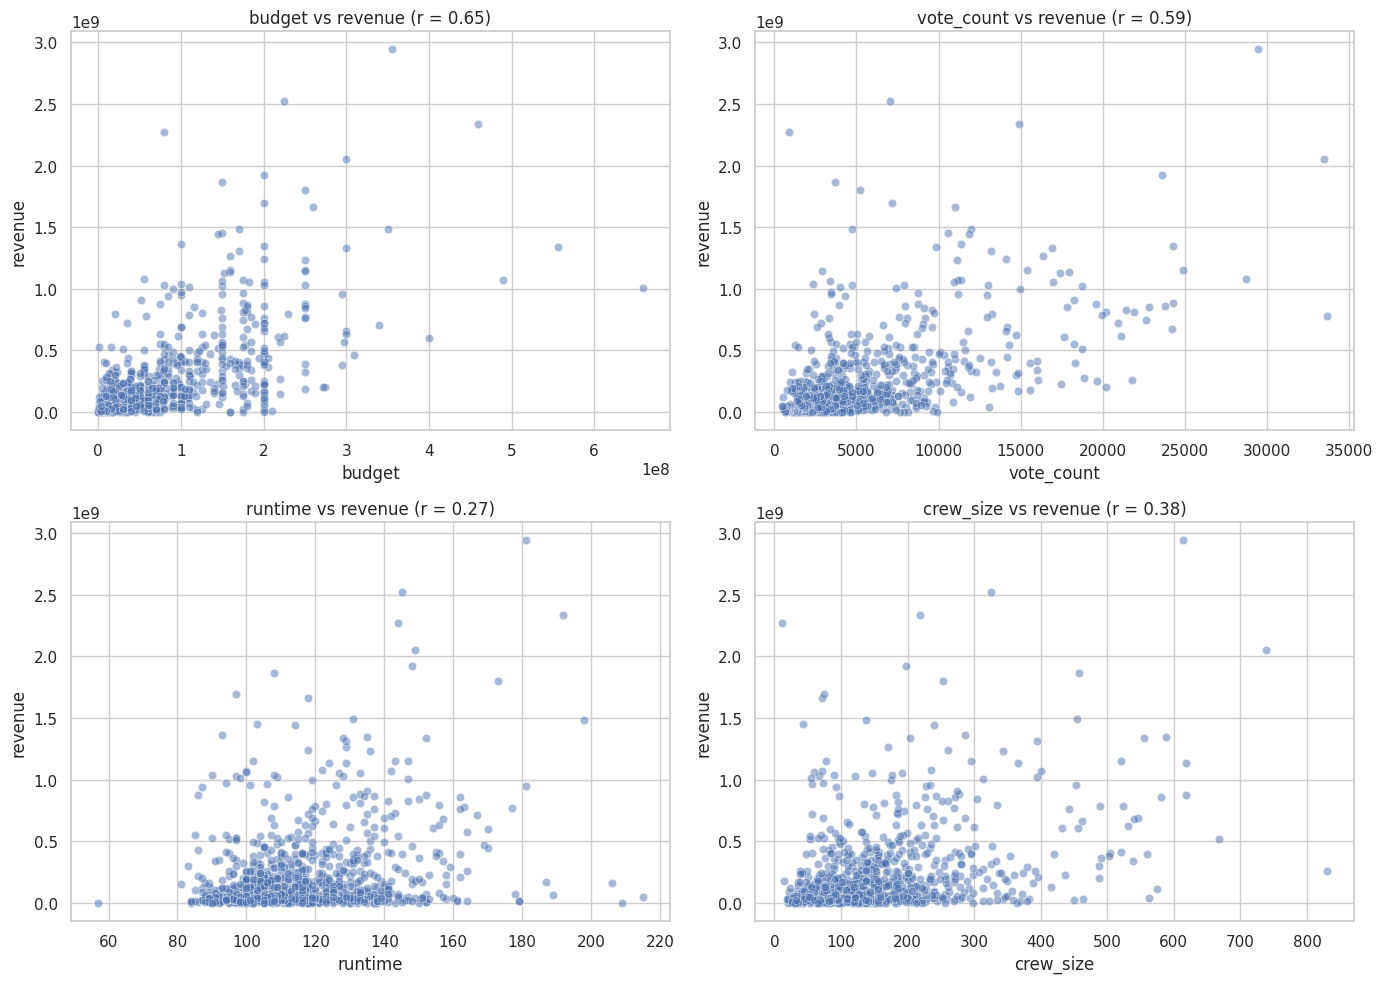

In [ ]:
pairs = [('budget', 'revenue'), ('vote_count', 'revenue'),
         ('runtime', 'revenue'), ('crew_size', 'revenue')]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (x, y) in zip(axes.ravel(), pairs):
    d = eda[[x, y]].dropna()
    sns.scatterplot(data=d, x=x, y=y, alpha=0.5, ax=ax)
    ax.set_title(f'{x} vs {y} (r = {d[x].corr(d[y]):.2f})')
plt.tight_layout()
plt.show()

I made scatter plots of four numeric variables against revenue to see whether they are related and how. I did this because revenue is my target and I want to know which inputs move together with it. Budget has the strongest relationship, with a correlation of 0.65, so movies with larger budgets tend to earn more, but the points spread out like a funnel, which means that expensive films can earn a lot or very little. Vote count has a correlation of 0.59, but it is only known after release, so I use it for understanding and not as a model input. Crew size has a moderate correlation of 0.38 and runtime a weak one of 0.27. The plots also contain a few extreme points far from the rest, for example revenues above 2.5 billion, which I will examine in the outlier section.



,median_revenue_M,count
genre,,
Adventure,319.3,256
Family,312.0,109
Animation,295.3,96
Science Fiction,213.9,188
Fantasy,195.3,144
Action,171.6,312
Music,154.6,21
Comedy,118.1,249
Crime,82.1,126


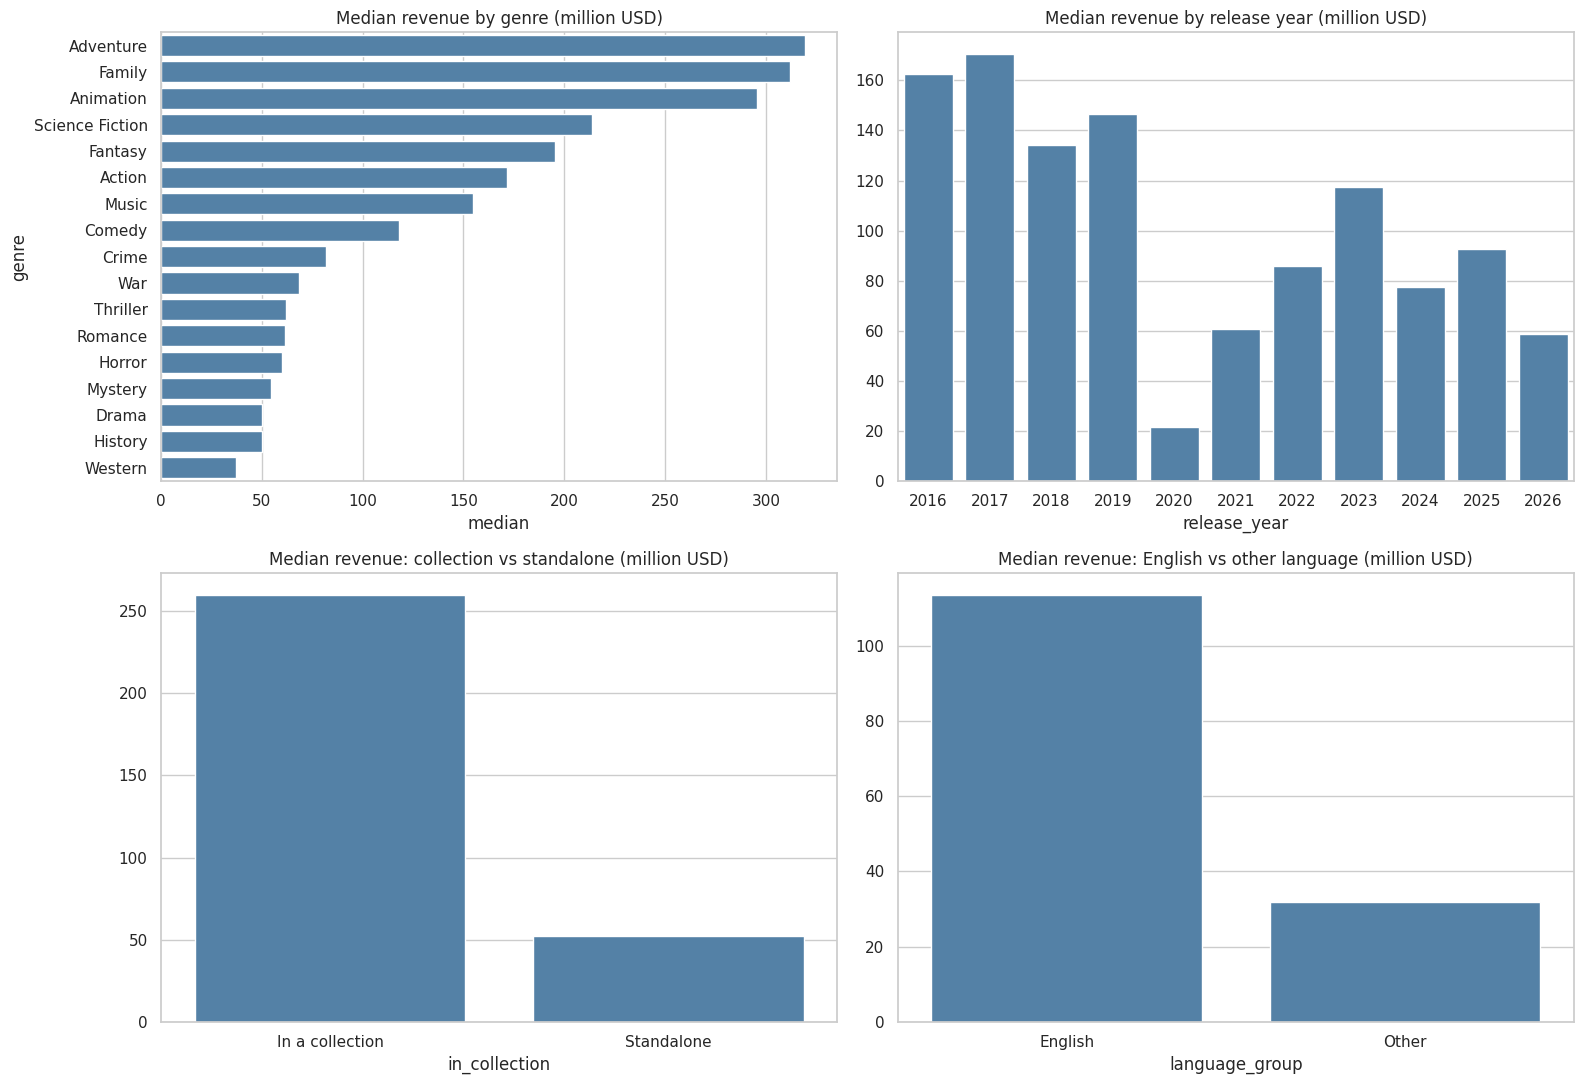

In [ ]:
eda['in_collection'] = eda['collection_name'].notna().map({True: 'In a collection', False: 'Standalone'})
eda['language_group'] = np.where(eda['original_language'] == 'en', 'English', 'Other')

g = eda[['genres', 'revenue']].copy()
g['genre'] = g['genres'].str.split('|')
g = g.explode('genre')
genre_stats = g.groupby('genre')['revenue'].agg(['median', 'count']).sort_values('median', ascending=False)
display((genre_stats.assign(median=lambda d: (d['median'] / 1e6).round(1))
         .rename(columns={'median': 'median_revenue_M'})))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.barplot(x=genre_stats['median'] / 1e6, y=genre_stats.index, color='steelblue', ax=axes[0, 0])
axes[0, 0].set_title('Median revenue by genre (million USD)')

ym = eda.groupby('release_year')['revenue'].median() / 1e6
sns.barplot(x=ym.index, y=ym.values, color='steelblue', ax=axes[0, 1])
axes[0, 1].set_title('Median revenue by release year (million USD)')

cm = eda.groupby('in_collection')['revenue'].median() / 1e6
sns.barplot(x=cm.index, y=cm.values, color='steelblue', ax=axes[1, 0])
axes[1, 0].set_title('Median revenue: collection vs standalone (million USD)')

lm = eda.groupby('language_group')['revenue'].median() / 1e6
sns.barplot(x=lm.index, y=lm.values, color='steelblue', ax=axes[1, 1])
axes[1, 1].set_title('Median revenue: English vs other language (million USD)')

plt.tight_layout()
plt.show()

I compared the median revenue across genres, release years, collection membership and language group with bar charts. I used the median and not the mean because revenue is strongly right skewed and a few blockbusters would dominate the averages. Adventure, Family and Animation have the highest median revenue, at about 300 million or more, followed by Science Fiction and Fantasy, while Drama, History and Western have the lowest, at about 50 million or less. Western has only 6 movies, Music 21 and War 24, so their medians are less reliable. Movies that belong to a collection have a median revenue of about 260 million, compared with about 52 million for standalone movies, and English language movies have a median of about 113 million, compared with about 32 million for other languages. By year, 2017 has the highest median and 2020 the lowest, which is consistent with the closure of cinemas during the pandemic, and 2026 is a partial year. These differences suggest that genre, collection membership and language carry useful information about revenue, and that franchise and family films earn more than average.

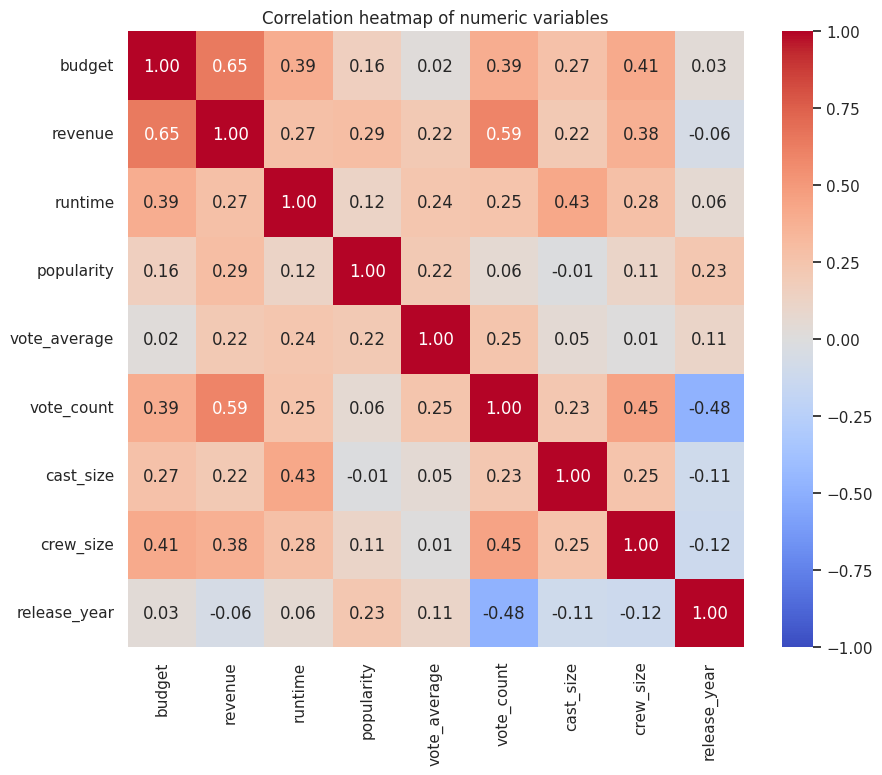

Correlation with revenue:
budget          0.65
vote_count      0.59
crew_size       0.38
popularity      0.29
runtime         0.27
vote_average    0.22
cast_size       0.22
release_year   -0.06
Name: revenue, dtype: float64


In [ ]:
corr_cols = ['budget', 'revenue', 'runtime', 'popularity', 'vote_average',
             'vote_count', 'cast_size', 'crew_size', 'release_year']
corr = eda[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True)
plt.title('Correlation heatmap of numeric variables')
plt.show()

print('Correlation with revenue:')
print(corr['revenue'].drop('revenue').sort_values(ascending=False).round(2))

I calculated the correlations among the numeric variables and displayed them as a heatmap, and I also listed the correlation of each variable with revenue. I did this to see which variables move together, which ones are most related to the target, and whether some inputs are so strongly related to each other that they may be redundant. Budget has the strongest correlation with revenue, at 0.65, followed by vote count at 0.59, crew size at 0.38, popularity at 0.29 and runtime at 0.27, while release year has almost no linear relation with revenue, at -0.06. Vote count has a negative correlation of -0.48 with release year, which is expected because older movies have had more time to collect votes. No pair of variables has a correlation above 0.65, so the inputs are not strongly redundant. Correlation only measures linear relationships, so the real relationships may be stronger or weaker than shown, and it does not prove cause and effect.

## Section 7: Skewness Analysis and Treatment

In [ ]:
sk_cols = ['budget', 'revenue', 'runtime', 'popularity',
           'vote_average', 'vote_count', 'cast_size', 'crew_size']

def skew_label(s):
    if s > 1:     return 'highly positive'
    if s > 0.5:   return 'moderately positive'
    if s >= -0.5: return 'approximately symmetric'
    if s >= -1:   return 'moderately negative'
    return 'highly negative'

skew = eda[sk_cols].skew().round(2)
skew_table = pd.DataFrame({'skewness': skew, 'type': skew.apply(skew_label)})
display(skew_table.sort_values('skewness', ascending=False))

,skewness,type
popularity,10.73,highly positive
cast_size,3.37,highly positive
revenue,3.11,highly positive
vote_count,2.35,highly positive
budget,2.06,highly positive
crew_size,1.89,highly positive
runtime,1.09,highly positive
vote_average,-0.07,approximately symmetric


I calculated the skewness of each numeric variable, where a value near 0 means a symmetric distribution, a positive value means a long tail to the right and a negative value means a long tail to the left. I did this to decide which variables need a transformation instead of transforming everything. Popularity is the most skewed, at 10.73, followed by cast size at 3.37, revenue at 3.11, vote count at 2.35, budget at 2.06 and crew size at 1.89, which agrees with the histograms and with the presence of a few blockbusters. Runtime has a skewness of 1.09, which is only slightly above the threshold, so I will check whether it really needs a transformation. Vote average is approximately symmetric, at -0.07, so I will leave it unchanged. No variable is negatively skewed. The highly skewed variables are candidates for a transformation, which I apply and compare in the next cells.

In [ ]:
cand = ['popularity', 'cast_size', 'revenue', 'vote_count', 'budget', 'crew_size', 'runtime']

comp = pd.DataFrame({
    'original': eda[cand].skew(),
    'sqrt': np.sqrt(eda[cand]).skew(),
    'log1p': np.log1p(eda[cand]).skew()
}).round(2)
display(comp)

,original,sqrt,log1p
popularity,10.73,5.34,1.64
cast_size,3.37,1.18,-0.37
revenue,3.11,1.26,-1.80
vote_count,2.35,1.19,0.17
budget,2.06,0.68,-2.15
crew_size,1.89,0.82,-0.19
runtime,1.09,0.78,0.50


I tested two common transformations on the skewed variables, the square root and the logarithm of one plus the value, and compared the skewness before and after. I did this to see which transformation works best for each variable instead of assuming that one method fits all. The logarithm brings cast size, crew size and vote count close to 0, and it reduces popularity from 10.73 to 1.64, which is a large improvement even though it remains skewed. For budget the logarithm overshoots, giving a skewness of -2.15, because a few very small budgets are stretched far to the left, so the square root, with 0.68, is the better choice. Revenue is not handled well by either transformation, since the square root leaves 1.26 and the logarithm gives -1.80, so I will decide how to treat the target later. Runtime has a skewness of only 1.09, its histogram is close to a bell shape and its long tail is made of genuinely long films, so I will leave it unchanged. A transformation that pushes the skewness far below 0 is not an improvement, because it replaces a right tail with a left tail.

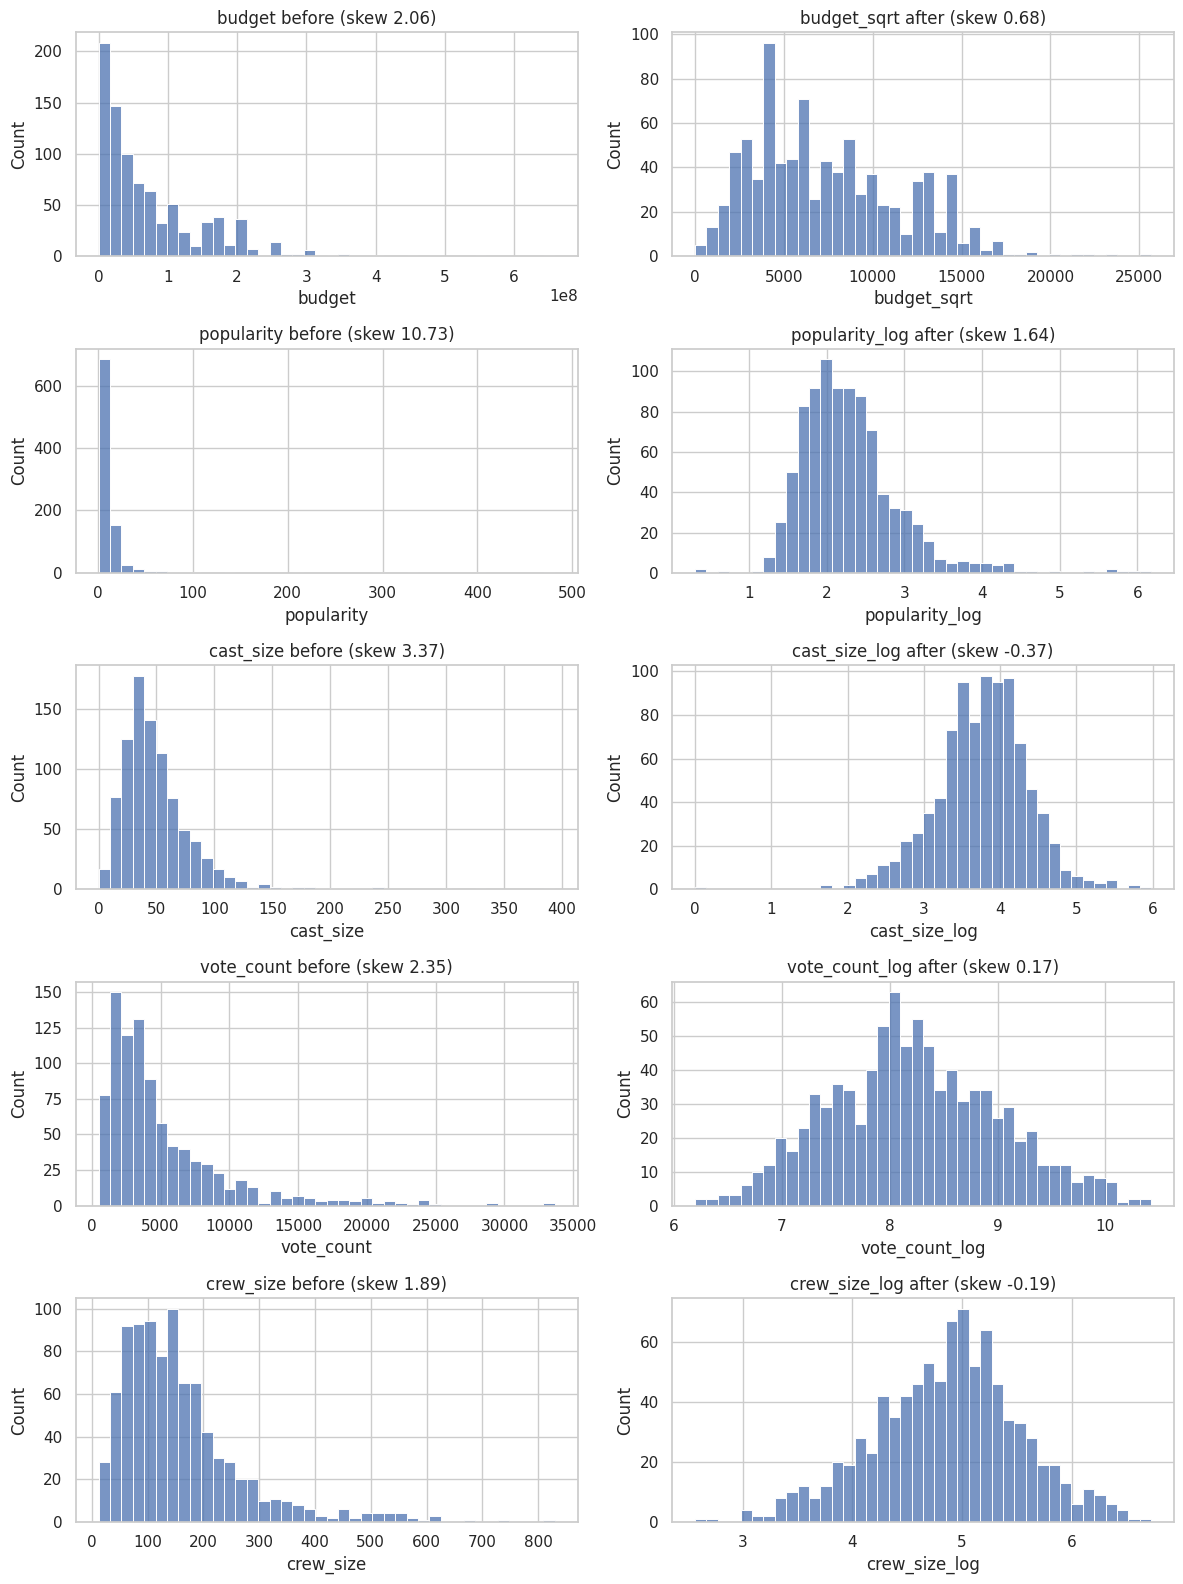

,before,after
budget_sqrt,2.06,0.68
popularity_log,10.73,1.64
cast_size_log,3.37,-0.37
vote_count_log,2.35,0.17
crew_size_log,1.89,-0.19


In [ ]:
transformed = eda.copy()
transformed['budget_sqrt'] = np.sqrt(eda['budget'])
for c in ['popularity', 'cast_size', 'vote_count', 'crew_size']:
    transformed[f'{c}_log'] = np.log1p(eda[c])

pairs = [('budget', 'budget_sqrt'), ('popularity', 'popularity_log'),
         ('cast_size', 'cast_size_log'), ('vote_count', 'vote_count_log'),
         ('crew_size', 'crew_size_log')]

fig, axes = plt.subplots(len(pairs), 2, figsize=(12, 16))
for i, (a, b) in enumerate(pairs):
    sns.histplot(transformed[a].dropna(), bins=40, ax=axes[i, 0])
    axes[i, 0].set_title(f'{a} before (skew {transformed[a].skew():.2f})')
    sns.histplot(transformed[b].dropna(), bins=40, ax=axes[i, 1])
    axes[i, 1].set_title(f'{b} after (skew {transformed[b].skew():.2f})')
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    'before': [transformed[a].skew() for a, b in pairs],
    'after': [transformed[b].skew() for a, b in pairs]
}, index=[b for a, b in pairs]).round(2)
display(summary)

I applied the chosen transformations, the square root for budget and the logarithm for popularity, cast size, vote count and crew size, and compared the histograms and skewness before and after. The histograms on the left are long tailed with most of the movies bunched at the low end, while the ones on the right are more spread out and closer to a bell shape. The skewness of budget fell from 2.06 to 0.68, popularity from 10.73 to 1.64, cast size from 3.37 to -0.37, vote count from 2.35 to 0.17 and crew size from 1.89 to -0.19. The transformations clearly improved the distributions, although popularity still has a right tail and the transformed budget has two groups, one of lower budget films and one of big studio films, which is a real feature of the data and not something a transformation can remove. I did not transform runtime or vote average because they were already close to symmetric, and I left revenue for the modeling section. In the final pipeline the transformations will be applied to the training and test data in the same way.

## Section 8: Outlier Detection Using the IQR Method

In [ ]:
out_cols = ['budget', 'revenue', 'runtime', 'cast_size', 'crew_size',
            'popularity', 'vote_count', 'vote_average']
rows = []
for c in out_cols:
    s = eda[c].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    below, above = (s < lo).sum(), (s > hi).sum()
    rows.append({'feature': c, 'Q1': q1, 'Q3': q3, 'IQR': iqr,
                 'lower_fence': lo, 'upper_fence': hi,
                 'below': below, 'above': above,
                 'outliers_%': round((below + above) / len(s) * 100, 1)})
iqr_table = pd.DataFrame(rows).set_index('feature')
display(iqr_table.round(2))

,Q1,Q3,IQR,lower_fence,upper_fence,below,above,outliers_%
feature,,,,,,,,
budget,18000000.00,1.040000e+08,8.600000e+07,-1.110000e+08,2.330000e+08,0,32,3.7
revenue,34276544.50,2.749754e+08,2.406989e+08,-3.267717e+08,6.360237e+08,0,85,9.5
runtime,102.00,1.280000e+02,2.600000e+01,6.300000e+01,1.670000e+02,1,17,2.0
cast_size,30.00,6.200000e+01,3.200000e+01,-1.800000e+01,1.100000e+02,0,35,3.9
crew_size,82.50,1.950000e+02,1.125000e+02,-8.625000e+01,3.637500e+02,0,51,5.7
popularity,5.41,1.222000e+01,6.810000e+00,-4.810000e+00,2.243000e+01,0,71,7.9
vote_count,2123.50,6.526000e+03,4.402500e+03,-4.480250e+03,1.312975e+04,0,59,6.6
vote_average,6.50,7.390000e+00,8.900000e-01,5.160000e+00,8.730000e+00,4,2,0.7



I calculated the first and third quartiles, the interquartile range and the lower and upper fences for each numeric variable, and counted the values that fall outside the fences. The lower fence is Q1 minus 1.5 times the IQR and the upper fence is Q3 plus 1.5 times the IQR. I did this to find the potential outliers and to see how many there are in each variable. Revenue has the most outliers, 85 or 9.5 percent, followed by popularity at 7.9 percent, vote count at 6.6 percent and crew size at 5.7 percent, and almost all of them lie above the upper fence. Budget has 32 outliers, all above 233 million, runtime has 18 and vote average has 6. The lower fences of the skewed variables are negative, so no low values are flagged in them, which means that this rule cannot find unusually small values such as a very tiny budget, and I will check those separately. These are potential outliers only, because the IQR rule assumes a fairly symmetric distribution and flags many legitimate values in skewed variables such as budget and revenue.



In [ ]:
print('Budgets below 100,000 USD:')
display(eda[eda['budget'] < 100000][['title', 'release_date', 'budget', 'revenue']].sort_values('budget'))

print('Top 8 budgets:')
display(eda.nlargest(8, 'budget')[['title', 'release_year', 'budget', 'revenue']])

print('Shortest and longest films:')
display(pd.concat([eda.nsmallest(4, 'runtime'), eda.nlargest(4, 'runtime')])[['title', 'release_year', 'runtime']])

print('Cast size outliers (top 5) and zeros:')
display(pd.concat([eda.nlargest(5, 'cast_size'), eda[eda['cast_size'] == 0]])[['title', 'release_year', 'cast_size']])

Budgets below 100,000 USD:


,title,release_date,budget,revenue
846,Swapped,2026-05-01,7.0,7.0
261,Terrifier,2018-01-25,35000.0,421798.0


Top 8 budgets:


,title,release_year,budget,revenue
515,Jurassic World Dominion,2022,658800000.0,1.004005e+09
660,Deadpool & Wolverine,2024,556800000.0,1.338074e+09
288,Star Wars: The Rise of Skywalker,2019,489900000.0,1.074144e+09
505,Avatar: The Way of Water,2022,460000000.0,2.334485e+09
761,Mission: Impossible - The Final Reckoning,2025,400000000.0,5.987671e+08
279,Avengers: Endgame,2019,356000000.0,2.942661e+09
747,Avatar: Fire and Ash,2025,350000000.0,1.486000e+09
583,Fast X,2023,340000000.0,7.047097e+08


Shortest and longest films:


,title,release_year,runtime
419,Host,2020,57
77,Lights Out,2016,81
633,Migration,2023,83
261,Terrifier,2018,84
710,The Brutalist,2024,215
305,The Irishman,2019,209
594,Killers of the Flower Moon,2023,206
747,Avatar: Fire and Ash,2025,198


Cast size outliers (top 5) and zeros:


,title,release_year,cast_size
684,Wicked,2024,394
464,"The French Dispatch of the Liberty, Kansas Eve...",2021,331
571,TÁR,2022,299
50,Jason Bourne,2016,243
537,Babylon,2022,243
687,Flow,2024,0


Before deciding what to do with the outliers I looked at the actual movies behind the extreme values. I did this because extreme budgets, runtimes or crew sizes can be real, and only impossible values should be treated as errors. The highest budgets belong to well known blockbusters such as Jurassic World Dominion, Deadpool and Wolverine, Star Wars: The Rise of Skywalker and the Avatar films, and their revenues match their budgets, so they are genuine. Terrifier has a budget of 35000 dollars, which is real because it is a very low budget horror film that earned more than 400000. The film Swapped has a budget of 7 dollars and a revenue of 7 dollars, which cannot be real and is most likely a placeholder or an entry error in TMDB, and the IQR rule did not flag it because the lower fences are negative. The longest films, such as The Brutalist and The Irishman, the shortest film Host, the large casts of Wicked and The French Dispatch, and Flow with no credited cast, are all plausible. I will keep the genuine extreme values and treat only the impossible ones.

Invalid rows:


,title,budget,revenue
846,Swapped,7.0,7.0


Rows before: 899 | after: 898
runtime: capped 18 values to [63.0, 167.0]
cast_size: capped 35 values to [-18.0, 110.0]
crew_size: capped 50 values to [-85.8, 364.2]


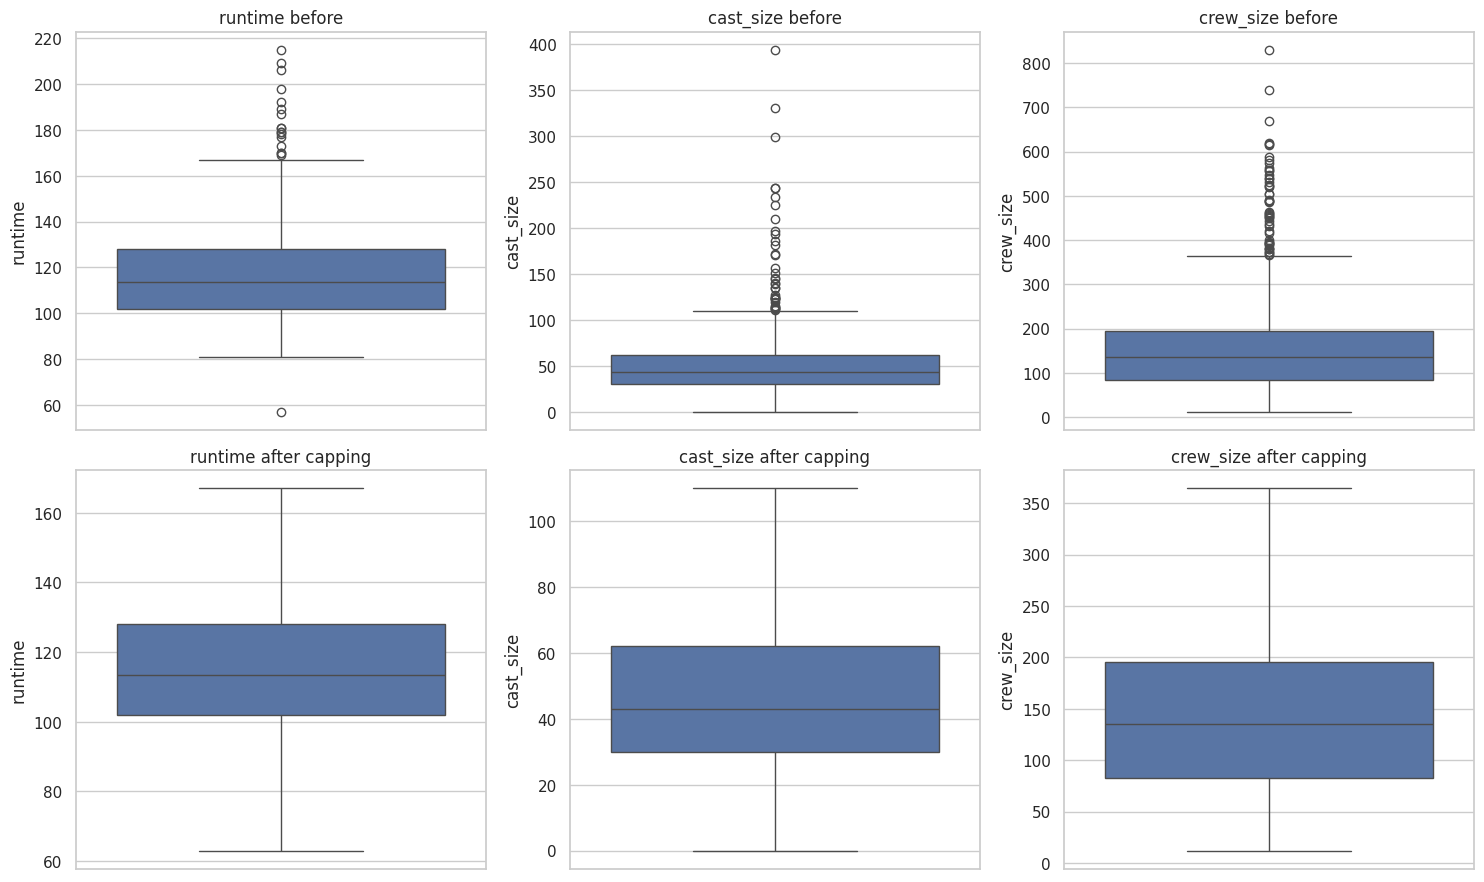

In [ ]:

invalid = (eda['revenue'] < 1000) | (eda['budget'] < 1000)
print('Invalid rows:')
display(eda[invalid][['title', 'budget', 'revenue']])
treated = eda[~invalid].copy()
print('Rows before:', len(eda), '| after:', len(treated))


cap_cols = ['runtime', 'cast_size', 'crew_size']
capped = treated.copy()
for c in cap_cols:
    q1, q3 = treated[c].quantile(0.25), treated[c].quantile(0.75)
    lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    n_cap = ((treated[c] < lo) | (treated[c] > hi)).sum()
    capped[c] = treated[c].clip(lower=lo, upper=hi)
    print(f'{c}: capped {n_cap} values to [{lo:.1f}, {hi:.1f}]')


fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for i, c in enumerate(cap_cols):
    sns.boxplot(y=treated[c], ax=axes[0, i]); axes[0, i].set_title(f'{c} before')
    sns.boxplot(y=capped[c], ax=axes[1, i]); axes[1, i].set_title(f'{c} after capping')
plt.tight_layout()
plt.show()

I treated the outliers according to what I found when I inspected them. The film Swapped has a budget and a revenue of 7 dollars, which are impossible values, so I removed it from the dataset, leaving 898 movies. The other extreme values are genuine, so I kept all of those rows. For runtime, cast size and crew size I capped the values at the IQR fences, which affected 18, 35 and 50 movies respectively and keeps every movie while limiting the influence of a few extreme cases on models that are sensitive to them. I did not cap budget, because the largest budgets belong to real blockbusters and carry the information that best explains revenue, and I deal with its skewness using the square root transformation. I also did not cap revenue because it is the target. The box plots before and after show that the extreme points above the whiskers are gone from the three capped variables, while the median and the box stay the same. The lower fence for cast size is negative, but no value was below it, so it had no effect. In the final pipeline the fences will be calculated on the training data only.

In [ ]:
capped.to_csv(f'{PROC_DIR}/tmdb_after_outlier_treatment.csv', index=False)
treated.to_csv(f'{PROC_DIR}/tmdb_invalid_removed.csv', index=False)
print('Saved:', capped.shape, treated.shape)

Saved: (898, 31) (898, 31)


I saved two datasets to Drive: the dataset after removing the invalid movie, and the dataset after capping the extreme values of runtime, cast size and crew size. I did this so that I can reload them after a Colab restart and continue with the next sections without repeating the outlier analysis, and so that the results of this section are kept as part of the project files. The output shows that both tables have 898 rows and 31 columns, which confirms that the only movie removed in this section was the one with impossible budget and revenue values.

## Section 9: Feature Selection and Feature Engineering

### SECTION 9A: Feature engineering



In [ ]:
def n_items(s):
    return 0 if (pd.isna(s) or s == 'Unknown') else s.count('|') + 1

feat = treated.copy()
feat['release_date'] = pd.to_datetime(feat['release_date'])
feat['release_year'] = feat['release_date'].dt.year
feat['release_month'] = feat['release_date'].dt.month
feat['release_weekday'] = feat['release_date'].dt.dayofweek
feat['is_summer_release'] = feat['release_month'].isin([5, 6, 7]).astype(int)
feat['is_holiday_release'] = feat['release_month'].isin([11, 12]).astype(int)
feat['n_genres'] = feat['genres'].apply(n_items)
feat['is_part_of_collection'] = feat['collection_name'].notna().astype(int)
feat['lang_en'] = (feat['original_language'] == 'en').astype(int)
feat['n_companies'] = feat['production_companies'].apply(n_items)
feat['n_countries'] = feat['production_countries'].apply(n_items)
feat['n_spoken_languages'] = feat['spoken_languages'].apply(n_items)
feat['budget_missing'] = feat['budget'].isnull().astype(int)

genre_dummies = feat['genres'].str.get_dummies(sep='|').add_prefix('genre_')

base_cols = ['budget', 'runtime', 'cast_size', 'crew_size',
             'release_year', 'release_month', 'release_weekday',
             'n_genres', 'n_companies', 'n_countries', 'n_spoken_languages',
             'is_part_of_collection', 'is_summer_release', 'is_holiday_release',
             'lang_en', 'budget_missing']
X_all = pd.concat([feat[base_cols], genre_dummies], axis=1)
y_all = feat['revenue']

print('Features:', X_all.shape[1], '| rows:', len(X_all))
print('Missing values per column (only those with gaps):')
print(X_all.isnull().sum()[X_all.isnull().sum() > 0])
print('Leakage check, columns not used as inputs: vote_average, vote_count, popularity, revenue')
display(X_all.head())

pd.concat([X_all, y_all], axis=1).to_csv(f'{PROC_DIR}/tmdb_features.csv', index=False)

Features: 33 | rows: 898
Missing values per column (only those with gaps):
budget    32
dtype: int64
Leakage check, columns not used as inputs: vote_average, vote_count, popularity, revenue


,budget,runtime,cast_size,crew_size,release_year,release_month,release_weekday,n_genres,n_companies,n_countries,...,genre_Fantasy,genre_History,genre_Horror,genre_Music,genre_Mystery,genre_Romance,genre_Science Fiction,genre_Thriller,genre_War,genre_Western
0,58000000.0,108,52,489,2016,2,1,3,4,1,...,0,0,0,0,0,0,0,0,0,0
1,250000000.0,147,104,296,2016,4,2,3,1,1,...,0,0,0,0,0,0,1,0,0,0
2,180000000.0,115,44,253,2016,10,1,3,1,1,...,1,0,0,0,0,0,0,0,0,0
3,175000000.0,122,106,194,2016,8,2,3,4,1,...,1,0,0,0,0,0,0,0,0,0
4,47000000.0,116,72,487,2016,11,3,3,3,1,...,0,0,0,0,1,0,1,0,0,0


I created new features from the dates and from the nested fields, using only information that is known before a movie is released. From the release date I took the year, the month and the day of the week, and I added flags for the summer release season, from May to July, and for the holiday season, in November and December, because big films are often scheduled in those periods. I also counted the genres, production companies, countries and spoken languages, created a flag for movies that belong to a collection and a flag for English language movies, and added one column for each genre. I added a flag that records whether the budget was missing, because the missing budgets are not random and the flag lets the model use that pattern. To avoid target leakage I left out vote average, vote count and popularity, which only exist after release, and of course revenue itself. The result is a table with 33 features and 898 movies, where only budget still has missing values, in 32 movies, which I will impute after splitting the data so that nothing from the test set influences the training. The outlier capping and the transformations from the earlier sections are not applied yet, because they will also be fitted on the training data only. I saved the feature table to Drive.

## NOTE:Forward feature selection and backward feature elimination are part of this section, but I perform them after the train-test split in Section 10. Feature selection learns from the data, so running it on the full dataset would let the test movies influence which features are chosen, which is a form of leakage. Placing it after the split means the selection is fitted on the training data only, as the instructions require.

#### check cell:

In [ ]:
small = feat.loc[y_all < 1_000_000, ['title', 'release_year', 'budget', 'revenue']].sort_values('revenue')
print('Movies with revenue under 1 million:', len(small))
display(small)

Movies with revenue under 1 million: 28


,title,release_year,budget,revenue
605,Society of the Snow,2023,65500000.0,1281.0
692,Damsel,2024,60000000.0,5000.0
708,The Idea of You,2024,NaN,36178.0
403,The Midnight Sky,2020,NaN,70018.0
736,Don't Move,2024,NaN,88489.0
391,The Trial of the Chicago 7,2020,35000000.0,107423.0
409,Mank,2020,25000000.0,122252.0
497,The Hand of God,2021,13050000.0,167909.0
449,Red Notice,2021,160000000.0,178143.0
796,A House of Dynamite,2025,NaN,181125.0


I listed the movies with a revenue below one million dollars because the minimum revenue in the training set was close to zero, and a revenue that small could be a data error like the film with a revenue of 7 dollars. The output shows 28 movies. A few are genuine small films with small budgets, such as Terrifier and Host, but most are well known films with large budgets, such as Red Notice and The Irishman, which were mainly released on streaming services with only a short cinema run. I handle these films in the next cell.




In [ ]:
scope_rule = (y_all < 1_000_000) & ((X_all['budget'] >= 10_000_000) | X_all['budget'].isnull())
print('Movies removed by the rule:', scope_rule.sum())
display(feat.loc[scope_rule, ['title', 'release_year', 'budget', 'revenue']].sort_values('revenue'))
print('Small revenue movies kept:')
display(feat.loc[(y_all < 1_000_000) & ~scope_rule, ['title', 'release_year', 'budget', 'revenue']])

X_all, y_all, feat = X_all[~scope_rule], y_all[~scope_rule], feat[~scope_rule]
print('Rows now:', len(X_all), '| missing budgets now:', X_all['budget'].isnull().sum())

pd.concat([X_all, y_all], axis=1).to_csv(f'{PROC_DIR}/tmdb_features_final.csv', index=False)

Movies removed by the rule: 22


,title,release_year,budget,revenue
605,Society of the Snow,2023,65500000.0,1281.0
692,Damsel,2024,60000000.0,5000.0
708,The Idea of You,2024,NaN,36178.0
403,The Midnight Sky,2020,NaN,70018.0
736,Don't Move,2024,NaN,88489.0
391,The Trial of the Chicago 7,2020,35000000.0,107423.0
409,Mank,2020,25000000.0,122252.0
497,The Hand of God,2021,13050000.0,167909.0
449,Red Notice,2021,160000000.0,178143.0
796,A House of Dynamite,2025,NaN,181125.0


Small revenue movies kept:


,title,release_year,budget,revenue
98,The Invitation,2016,1000000.0,354835.0
261,Terrifier,2018,35000.0,421798.0
352,Vivarium,2019,4000000.0,488000.0
419,Host,2020,100000.0,443807.0
425,Riders of Justice,2020,5300000.0,679505.0
734,Subservience,2024,4400000.0,262793.0


Rows now: 876 | missing budgets now: 24


When I checked the movies with a revenue below one million dollars I found 28 of them, and most were well known films with large budgets, such as Red Notice, The Gray Man, The Irishman, Don't Look Up and Society of the Snow. These are mainly streaming releases that had only a short cinema run, so their reported revenue does not measure their success in the way box office revenue does for a cinema release. Keeping them would teach the model that a large budget can lead to almost no revenue, which is not true for the movies I want to predict. I therefore removed movies whose revenue is below one million and whose budget is at least ten million or unknown. This rule removed 22 movies and kept 6 genuine small films, The Invitation, Terrifier, Vivarium, Host, Riders of Justice and Subservience, whose small revenues match their small budgets. I applied the rule before the train-test split because it decides which movies are in scope and does not learn anything from the data. The dataset now has 876 movies, and 24 of them still have a missing budget. A simple rule can also catch borderline cases, for example Guns Akimbo, which had a small cinema and on demand release, and some streaming releases with somewhat larger revenues may remain, so my model is best understood as predicting cinema box office revenue.

## Section 10: Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

revenue_bins = pd.qcut(y_all, q=5, labels=False)
X_train, X_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=SEED, stratify=revenue_bins)

print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Train share: {:.1%}'.format(len(X_train) / len(X_all)))

compare = pd.DataFrame({'train': y_train.describe(), 'test': y_test.describe()})
display((compare / 1e6).round(1).rename(index={'count': 'count (millions, ignore)'}))

print('Missing budget, train:', X_train['budget'].isnull().sum(), '| test:', X_test['budget'].isnull().sum())

pd.Series(X_train.index, name='train_index').to_csv(f'{PROC_DIR}/train_index.csv', index=False)
pd.Series(X_test.index, name='test_index').to_csv(f'{PROC_DIR}/test_index.csv', index=False)

Train: (700, 33) | Test: (176, 33)
Train share: 79.9%


,train,test
"count (millions, ignore)",0.0,0.0
mean,232.4,252.3
std,336.9,369.7
min,0.4,0.3
25%,37.1,39.2
50%,111.8,105.0
75%,290.1,283.4
max,2942.7,2052.4


Missing budget, train: 20 | test: 4


I divided the dataset into 80 percent training data and 20 percent testing data, which gave 700 movies for training and 176 for testing, since 20 percent of 876 rounds up to 176. Because revenue is very skewed, a purely random split could put a different share of blockbusters into each part, so I stratified the split on five revenue groups, which makes the training and test sets cover the same range of revenues. I used my team's seed as the random state so that the split can be reproduced. The median revenue is about 112 million in the training set and 105 million in the test set, and the quartiles are similar, so the two sets are comparable. The mean of the test set is somewhat higher, about 252 million against 232 million, because a few blockbusters have a large effect on the mean of a small set, which is why I compare the medians. The 24 movies with a missing budget were split into 20 in training and 4 in testing. From this point every step that learns from the data, including imputation, capping, transformation, scaling and feature selection, will be fitted on the training set only and then applied to the test set without refitting, and the test set will stay untouched until the final evaluation. I saved the indexes of both sets to Drive so the split can be recreated.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer

class IQRCapper(BaseEstimator, TransformerMixin):

    def __init__(self, k=1.5):
        self.k = k
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.feature_names_in_ = np.array(X.columns)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        self.lower_ = (q1 - self.k * (q3 - q1)).values
        self.upper_ = (q3 + self.k * (q3 - q1)).values
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(lower=self.lower_, upper=self.upper_, axis=1)
    def get_feature_names_out(self, input_features=None):
        return self.feature_names_in_

other_num = ['release_year', 'release_month', 'release_weekday',
             'n_genres', 'n_companies', 'n_countries', 'n_spoken_languages']
binary_cols = ['is_part_of_collection', 'is_summer_release', 'is_holiday_release',
               'lang_en', 'budget_missing'] + [c for c in X_all.columns if c.startswith('genre_')]

preprocessor = ColumnTransformer([
    ('budget', Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('sqrt', FunctionTransformer(np.sqrt, feature_names_out='one-to-one')),
                         ('scale', StandardScaler())]), ['budget']),
    ('cast_crew', Pipeline([('cap', IQRCapper()),
                            ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
                            ('scale', StandardScaler())]), ['cast_size', 'crew_size']),
    ('runtime', Pipeline([('cap', IQRCapper()), ('scale', StandardScaler())]), ['runtime']),
    ('other_num', StandardScaler(), other_num),
    ('binary', 'passthrough', binary_cols),
], verbose_feature_names_out=False).set_output(transform='pandas')

X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

print('Train:', X_train_prep.shape, '| Test:', X_test_prep.shape)
print('Missing values after preprocessing, train:', X_train_prep.isnull().sum().sum(),
      '| test:', X_test_prep.isnull().sum().sum())
print('Budget median learned from train:',
      preprocessor.named_transformers_['budget'].named_steps['impute'].statistics_[0])
cap = preprocessor.named_transformers_['runtime'].named_steps['cap']
print('Runtime fences learned from train:', cap.lower_, cap.upper_)

scaled = ['budget', 'cast_size', 'crew_size', 'runtime'] + other_num
display(pd.DataFrame({'train_mean': X_train_prep[scaled].mean(),
                      'test_mean': X_test_prep[scaled].mean()}).round(2))

pd.concat([X_train_prep, y_train], axis=1).to_csv(f'{PROC_DIR}/train_preprocessed.csv', index=False)
pd.concat([X_test_prep, y_test], axis=1).to_csv(f'{PROC_DIR}/test_preprocessed.csv', index=False)

Train: (700, 33) | Test: (176, 33)
Missing values after preprocessing, train: 0 | test: 0
Budget median learned from train: 41000000.0
Runtime fences learned from train: [64.5] [164.5]


,train_mean,test_mean
budget,0.0,0.02
cast_size,0.0,-0.05
crew_size,-0.0,0.02
runtime,-0.0,0.07
release_year,0.0,0.07
release_month,0.0,0.00
release_weekday,0.0,-0.03
n_genres,-0.0,-0.04
n_companies,-0.0,0.04
n_countries,-0.0,0.02


I put all the preprocessing steps into one pipeline and fitted it on the training data only, then applied the fitted pipeline to the test data without refitting. Budget is imputed with the median of the training set, which is 41 million dollars, then square rooted and scaled. Cast size and crew size are capped at fences learned from the training set, log transformed and scaled, and runtime is capped between 64.5 and 164.5 minutes, which are the fences learned from the training set, and scaled. These fences differ slightly from the ones I found on the full dataset in the outlier section, which shows that they now come from the training data alone. The date parts and the counts are scaled, and the flags and genre columns are kept as 0 and 1. The output shows that there are no missing values left in either set. The table compares the means of the scaled features: in the training set they are all 0, because the scaler learned its values from it, while in the test set they are close to 0 but not exactly 0, which confirms that the test data did not influence the preprocessing. I saved the preprocessed training and test sets to Drive.

### SECTION 9B CONTINUATION: Forward feature selection and backward feature elimination (training data only)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

y_train_log = np.log1p(y_train)
print('Skewness of training revenue: raw {:.2f} | sqrt {:.2f} | log {:.2f}'.format(
    y_train.skew(), np.sqrt(y_train).skew(), y_train_log.skew()))

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
all_feats = list(X_train_prep.columns)

def cv_r2(cols):
    return cross_val_score(LinearRegression(), X_train_prep[cols], y_train_log,
                           cv=cv, scoring='r2').mean()

selected, remaining, best, fwd_path = [], all_feats.copy(), -np.inf, []
while remaining:
    scores = {c: cv_r2(selected + [c]) for c in remaining}
    c_best = max(scores, key=scores.get)
    if scores[c_best] - best < 0.001:
        break
    selected.append(c_best)
    remaining.remove(c_best)
    best = scores[c_best]
    fwd_path.append({'step': len(selected), 'added': c_best, 'cv_r2': round(best, 4)})

forward_features = selected.copy()
display(pd.DataFrame(fwd_path))
print('Forward selection kept', len(forward_features), 'features, CV R2 =', round(best, 4))

Skewness of training revenue: raw 3.24 | sqrt 1.30 | log -0.65


,step,added,cv_r2
0,1,budget,0.4263
1,2,is_part_of_collection,0.4852
2,3,budget_missing,0.5197
3,4,genre_Animation,0.5335
4,5,crew_size,0.5486
5,6,n_countries,0.5571
6,7,cast_size,0.5626
7,8,n_genres,0.5653
8,9,release_weekday,0.5668
9,10,release_year,0.5678


Forward selection kept 11 features, CV R2 = 0.5689


I applied forward feature selection on the training data only. It starts with no features and, at each step, adds the feature that gives the largest improvement in the cross validated R squared of a linear regression, stopping when no feature improves it by at least 0.001. I used five fold cross validation on the training set, so the test set played no part. I used the logarithm of revenue as the target, because the skewness of the training revenue is 3.24 on the original scale, 1.30 after a square root and -0.65 after the logarithm, so the logarithm gives the most symmetric target and prevents a few blockbusters from dominating a linear model. Budget was chosen first and on its own reaches an R squared of 0.43, followed by collection membership, the missing budget flag and the animation genre, which together raise it to 0.53. The process stopped after 11 features with an R squared of 0.569, and the last few features, such as release year and runtime, each added very little.

In [ ]:
current = all_feats.copy()
best = cv_r2(current)
bwd_path = [{'step': 0, 'removed': '(start: all features)', 'cv_r2': round(best, 4)}]
while len(current) > 1:
    scores = {c: cv_r2([x for x in current if x != c]) for c in current}
    c_drop = max(scores, key=scores.get)
    if scores[c_drop] < best - 0.001:
        break
    current.remove(c_drop)
    best = scores[c_drop]
    bwd_path.append({'step': len(bwd_path), 'removed': c_drop, 'cv_r2': round(best, 4)})

backward_features = current.copy()
display(pd.DataFrame(bwd_path))
print('Backward elimination kept', len(backward_features), 'features, CV R2 =', round(best, 4))

,step,removed,cv_r2
0,0,(start: all features),0.5427
1,1,is_holiday_release,0.5462
2,2,release_month,0.5491
3,3,n_companies,0.5510
4,4,n_spoken_languages,0.5520
5,5,lang_en,0.5529
6,6,is_summer_release,0.5530
7,7,genre_Action,0.5530
8,8,genre_Western,0.5562
9,9,genre_Adventure,0.5580


Backward elimination kept 12 features, CV R2 = 0.5694


I also applied backward feature elimination on the training data only. It starts with all 33 features and, at each step, removes the feature whose removal hurts the cross validated R squared the least, stopping when any further removal would lower the score by more than 0.001. With all features the R squared was 0.543, and removing features actually improved it, which shows that many of them added noise rather than information. The flags for summer and holiday releases, the release month, the number of companies and spoken languages, the English language flag and most of the genre columns were removed. The process kept 12 features with an R squared of 0.569, which is almost the same score as forward selection.

### SECTION 9C: Final feature set

In [ ]:
common = [f for f in forward_features if f in backward_features]
union = forward_features + [f for f in backward_features if f not in forward_features]

cands = {'all features': all_feats, 'forward': forward_features,
         'backward': backward_features, 'intersection': common, 'union': union}
rows = []
for name, cols in cands.items():
    s = cross_val_score(LinearRegression(), X_train_prep[cols], y_train_log, cv=cv, scoring='r2')
    rows.append({'set': name, 'n_features': len(cols), 'cv_r2_mean': round(s.mean(), 4), 'cv_r2_std': round(s.std(), 4)})
sets_table = pd.DataFrame(rows).set_index('set')
display(sets_table)

membership = pd.DataFrame({'forward': [f in forward_features for f in union],
                           'backward': [f in backward_features for f in union]}, index=union)
display(membership)

best_score = sets_table['cv_r2_mean'].max()
ok = sets_table[sets_table['cv_r2_mean'] >= best_score - 0.002].sort_values('n_features')
final_name = ok.index[0]
final_features = cands[final_name]
print('Chosen set:', final_name, '|', len(final_features), 'features')
print(final_features)

,n_features,cv_r2_mean,cv_r2_std
set,,,
all features,33,0.5427,0.0357
forward,11,0.5689,0.0316
backward,12,0.5694,0.0322
intersection,10,0.5678,0.0288
union,13,0.5698,0.0344


,forward,backward
budget,True,True
is_part_of_collection,True,True
budget_missing,True,True
genre_Animation,True,True
crew_size,True,True
n_countries,True,True
cast_size,True,False
n_genres,True,True
release_weekday,True,True
release_year,True,True


Chosen set: intersection | 10 features
['budget', 'is_part_of_collection', 'budget_missing', 'genre_Animation', 'crew_size', 'n_countries', 'n_genres', 'release_weekday', 'release_year', 'runtime']


I compared five candidate feature sets with the same five fold cross validation on the training data: all 33 features, the forward selection result, the backward elimination result, the features chosen by both methods, and the features chosen by either method. Every selected set scored better than using all features, with an R squared of about 0.57 against 0.54, which shows that removing weak features reduced noise. The scores of the selected sets are practically the same, so I chose the smallest set whose score is within 0.002 of the best one. This is the intersection of the two methods, with 10 features and an R squared of 0.568, only 0.002 below the union. It also has the lowest variation across the folds, so it is the most stable choice, and a smaller model is easier to explain and less likely to overfit. The final features are budget, collection membership, the missing budget flag, the animation genre, crew size, the number of production countries, the number of genres, the release weekday, the release year and runtime. All of them are known before a movie is released, so there is no target leakage. Release weekday contributed very little and should be seen as a weak feature, but I kept it because both methods selected it.

## Section 11: Regression Model Development


In [ ]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

class ColumnSelector(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return X[self.columns]
    def get_feature_names_out(self, input_features=None):
        return np.array(self.columns)

def make_model(reg):
    return Pipeline([
        ('prep', clone(preprocessor)),
        ('select', ColumnSelector(final_features)),
        ('model', TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1)),
    ]).set_output(transform='pandas')

def metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {'MAE_M': mean_absolute_error(y_true, y_pred) / 1e6, 'MSE': mse,
            'RMSE_M': np.sqrt(mse) / 1e6, 'R2': r2_score(y_true, y_pred)}

TRAINING_TIME = datetime.now()
models = {
    'Ridge': make_model(Ridge(alpha=1.0)),
    'Random Forest': make_model(RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1)),
    'Gradient Boosting': make_model(GradientBoostingRegressor(random_state=SEED)),
}

rows = []
for name, m in models.items():
    m.fit(X_train, y_train)
    for split, X_, y_ in [('train', X_train, y_train), ('test', X_test, y_test)]:
        rows.append({'model': name, 'set': split, **metrics(y_, m.predict(X_))})

results = pd.DataFrame(rows)
display(results.pivot(index='model', columns='set', values=['MAE_M', 'RMSE_M', 'R2']).round(3))
print('Training time:', TRAINING_TIME.isoformat(timespec='seconds'))

MAE_M            RMSE_M              R2       
set                   test    train     test    train   test  train
model                                                              
Gradient Boosting  133.750   90.404  256.831  180.988  0.515  0.711
Random Forest      141.473   53.721  272.164  125.241  0.455  0.862
Ridge              128.613  130.713  246.240  318.834  0.554  0.103

Training time: 2026-11-25T21:04:35


I trained three regression models on the same 10 selected features and the same training data: ridge regression, random forest and gradient boosting. I chose ridge regression as a simple and interpretable linear model whose regularization keeps the coefficients stable, random forest because it can capture non linear effects and interactions and is robust to outliers, and gradient boosting because it builds trees step by step to correct earlier errors and is often the most accurate on tabular data. Each model is a single pipeline that contains the preprocessing fitted on the training data, the selection of the final features and the model, which is trained on the logarithm of revenue while its predictions are converted back to dollars, so all errors are reported in real dollars. On the test set ridge regression performed best, with a mean absolute error of about 129 million dollars, a root mean squared error of about 246 million and an R squared of 0.55, followed by gradient boosting with an R squared of 0.52 and random forest with 0.46. Random forest fits the training data much better than the test data, with an R squared of 0.86 against 0.46, which is a clear sign of overfitting, and gradient boosting shows the same pattern to a smaller degree, with 0.71 against 0.52. Ridge regression shows the opposite pattern, an R squared of only 0.10 on the training data, even though its mean absolute error is almost the same on both sets, about 131 million on training and 129 million on test. This suggests that a few very large errors on the training set are lowering its R squared, and I examine this in the next cell.



In [ ]:
print('R2 on the log scale (what the models were trained on):')
for name, m in models.items():
    r_tr = r2_score(np.log1p(y_train), np.log1p(m.predict(X_train)))
    r_te = r2_score(np.log1p(y_test), np.log1p(m.predict(X_test)))
    print(f'  {name:18s} train {r_tr:.3f} | test {r_te:.3f}')

ridge_pred = models['Ridge'].predict(X_train)
err = pd.DataFrame({'actual_M': y_train / 1e6, 'predicted_M': ridge_pred / 1e6,
                    'budget_M': X_train['budget'] / 1e6})
err['abs_error_M'] = (err['actual_M'] - err['predicted_M']).abs()
print('\nRidge: the 5 largest training errors')
display(err.nlargest(5, 'abs_error_M').round(1))

sq = (y_train - ridge_pred) ** 2
print('Share of Ridge total squared training error from the 5 worst movies: {:.0%}'.format(
    sq.nlargest(5).sum() / sq.sum()))

R2 on the log scale (what the models were trained on):
  Ridge              train 0.583 | test 0.562
  Random Forest      train 0.940 | test 0.532
  Gradient Boosting  train 0.805 | test 0.515

Ridge: the 5 largest training errors


,actual_M,predicted_M,budget_M,abs_error_M
503,1004.0,5861.6,658.8,4857.5
288,1074.1,3592.4,489.9,2518.2
644,1338.1,3541.6,556.8,2203.6
804,2270.7,223.3,80.0,2047.4
807,2523.1,761.8,225.0,1761.3


Share of Ridge total squared training error from the 5 worst movies: 59%



To understand why ridge regression had a much lower R squared on the training data than on the test data, I measured the R squared of all three models on the logarithmic scale on which they were trained and looked at the largest errors of ridge regression. On the logarithmic scale ridge regression scores 0.58 on training and 0.56 on test, so it is consistent and does not overfit, while random forest scores 0.94 against 0.53 and gradient boosting 0.81 against 0.52, which confirms that the tree models overfit. The five largest ridge errors on the training data belong to blockbusters. The three with the highest budgets, Jurassic World Dominion, Star Wars: The Rise of Skywalker and Deadpool and Wolverine, were predicted to earn between 3.5 and 5.9 billion dollars, much more than their real revenues of about 1 to 1.3 billion, because the linear model extends the budget trend too far for budgets that are far above the rest, and converting the prediction back from the logarithm to dollars magnifies the error. Two other films earned far more than their budgets suggested, which a budget based model cannot anticipate. These five movies alone account for 59 percent of the total squared error, which explains the low R squared in dollars. This shows that R squared and RMSE in dollars are dominated by a handful of extreme films, and that ridge regression is unreliable for movies with exceptionally large budgets.



## Section 12: Model Evaluation and Performance Analysis



In [ ]:
test_tbl = (results[results['set'] == 'test']
            .set_index('model')[['MAE_M', 'MSE', 'RMSE_M', 'R2']]
            .rename(columns={'MAE_M': 'MAE (M$)', 'RMSE_M': 'RMSE (M$)'}))
test_tbl['MSE'] = test_tbl['MSE'].map('{:.3e}'.format)
test_tbl['R2 log scale'] = [r2_score(np.log1p(y_test), np.log1p(models[m].predict(X_test)))
                            for m in test_tbl.index]
display(test_tbl.round(3).sort_values('R2', ascending=False))

gap = results.pivot(index='model', columns='set', values='R2')
gap['gap (train - test)'] = gap['train'] - gap['test']
display(gap.round(3))

,MAE (M$),MSE,RMSE (M$),R2,R2 log scale
model,,,,,
Ridge,128.613,6.063e+16,246.240,0.554,0.562
Gradient Boosting,133.750,6.596e+16,256.831,0.515,0.515
Random Forest,141.473,7.407e+16,272.164,0.455,0.532


set,test,train,gap (train - test)
model,,,
Gradient Boosting,0.515,0.711,0.196
Random Forest,0.455,0.862,0.407
Ridge,0.554,0.103,-0.451


I put the test results of the three models into one comparison table with the mean absolute error, the mean squared error, the root mean squared error and the R squared, and added the R squared on the logarithmic scale. Ridge regression is the best on every test metric, with a mean absolute error of about 129 million dollars, a root mean squared error of about 246 million and an R squared of 0.554, ahead of gradient boosting with 0.515 and random forest with 0.455. The mean squared error is very large because it is measured in squared dollars, so the root mean squared error, which is back in dollars, is easier to interpret. On the logarithmic scale random forest scores slightly better than gradient boosting, because that scale treats all movies more equally, while the dollar metrics are dominated by the blockbusters. The second table compares the training and test R squared. Random forest has a gap of 0.41 and gradient boosting a gap of 0.20, which shows that both tree models overfit and memorize part of the training data. Ridge regression has a negative gap, but this is not underfitting, because its R squared on the logarithmic scale is 0.58 on training and 0.56 on test, and the low training value in dollars comes from a few blockbusters with very large errors, as shown in Section 11.


In [ ]:
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

def log_r2(y_true, y_pred):
    return r2_score(np.log1p(y_true), np.log1p(np.clip(y_pred, 0, None)))

scoring = {'R2': 'r2', 'MAE': 'neg_mean_absolute_error',
           'RMSE': 'neg_root_mean_squared_error', 'R2_log': make_scorer(log_r2)}

cv_rows = []
for name, m in models.items():
    s = cross_validate(clone(m), X_train, y_train, cv=cv, scoring=scoring)
    cv_rows.append({'model': name,
                    'R2 mean': s['test_R2'].mean(), 'R2 std': s['test_R2'].std(),
                    'R2_log mean': s['test_R2_log'].mean(), 'R2_log std': s['test_R2_log'].std(),
                    'MAE mean (M$)': -s['test_MAE'].mean() / 1e6,
                    'RMSE mean (M$)': -s['test_RMSE'].mean() / 1e6})
cv_table = pd.DataFrame(cv_rows).set_index('model')
display(cv_table.round(3))

,R2 mean,R2 std,R2_log mean,R2_log std,MAE mean (M$),RMSE mean (M$)
model,,,,,,
Ridge,0.194,0.427,0.568,0.028,132.872,297.492
Random Forest,0.432,0.064,0.553,0.046,125.633,250.338
Gradient Boosting,0.376,0.092,0.570,0.031,128.324,258.948


I ran five fold cross validation on the training data for each model to check how stable their performance is, refitting the whole pipeline inside each fold so that no information leaked between folds. The results change the picture given by the test set. Ridge regression has a mean R squared in dollars of only 0.19 with a very large standard deviation of 0.43, because in the folds that contain the films with the largest budgets it predicts revenues that are far too high, while on the logarithmic scale it is stable at 0.57. This means that its first place on the test set was partly due to the split, since those extreme films happened to be in the training set. Random forest is the most stable in dollars, with an R squared of 0.43 and a standard deviation of 0.06, and has the lowest average errors, but it overfits strongly. Gradient boosting has the highest R squared on the logarithmic scale, 0.57, a stable performance with a standard deviation of 0.09 in dollars, and less overfitting than random forest.


### Best model selection

On the test set ridge regression is the best performing model, with the lowest errors and an R squared of 0.554. However, cross validation shows that its results are unstable and depend on which films are in the test set, and that it can predict extremely high revenues for films with exceptionally large budgets. Random forest is stable but overfits the training data the most. Gradient boosting is second on the test set, has the best and most stable cross validated R squared on the logarithmic scale, and overfits less than random forest. I therefore select gradient boosting as the most reliable model and tune its hyperparameters to reduce its overfitting, while I keep ridge regression as a simple baseline for comparison.

### Hyperparameter tuning

In [ ]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'model__regressor__n_estimators': [100, 200, 300, 500],
    'model__regressor__learning_rate': [0.01, 0.03, 0.05, 0.1],
    'model__regressor__max_depth': [2, 3, 4],
    'model__regressor__min_samples_leaf': [5, 10, 20, 30],
    'model__regressor__subsample': [0.6, 0.8, 1.0],
}

search = RandomizedSearchCV(clone(models['Gradient Boosting']), param_dist, n_iter=40,
                            cv=cv, scoring='neg_mean_absolute_error',
                            random_state=SEED, n_jobs=-1)
search.fit(X_train, y_train)
gb_tuned = search.best_estimator_

print('Best parameters:')
for k, v in search.best_params_.items():
    print(' ', k.replace('model__regressor__', ''), '=', v)
print('Best CV MAE (M$):', round(-search.best_score_ / 1e6, 2))

rows = []
for label, m in [('before tuning', models['Gradient Boosting']), ('after tuning', gb_tuned)]:
    tr, te = metrics(y_train, m.predict(X_train)), metrics(y_test, m.predict(X_test))
    rows.append({'model': label, 'train R2': tr['R2'], 'test R2': te['R2'],
                 'test MAE (M$)': te['MAE_M'], 'test RMSE (M$)': te['RMSE_M'],
                 'test MSE': '{:.3e}'.format(te['MSE']),
                 'test R2 log': r2_score(np.log1p(y_test), np.log1p(m.predict(X_test)))})
display(pd.DataFrame(rows).set_index('model').round(3))

Best parameters:
  subsample = 0.6
  n_estimators = 200
  min_samples_leaf = 10
  max_depth = 2
  learning_rate = 0.03
Best CV MAE (M$): 119.67


,train R2,test R2,test MAE (M$),test RMSE (M$),test MSE,test R2 log
model,,,,,,
before tuning,0.711,0.515,133.750,256.831,6.596e+16,0.515
after tuning,0.497,0.462,135.519,270.381,7.311e+16,0.560


I tuned the gradient boosting model with a randomized search that tried 40 combinations of the number of trees, the learning rate, the tree depth, the minimum number of movies in a leaf and the share of movies used by each tree, scoring each combination by its mean absolute error in five fold cross validation on the training data. I used the mean absolute error because it is measured in dollars and is less dominated by a few blockbusters than the root mean squared error. The best combination uses 200 shallow trees with a depth of 2, a small learning rate of 0.03, at least 10 movies per leaf and 60 percent of the movies for each tree, which are all settings that reduce overfitting. Tuning lowered the cross validated mean absolute error from 128 to 120 million dollars, and the gap between training and test R squared fell from 0.20 to 0.04, so the model no longer memorizes the training data. On the test set the R squared on the logarithmic scale improved from 0.52 to 0.56, but the R squared in dollars fell from 0.52 to 0.46 and the mean absolute error rose slightly, from 134 to 136 million. The tuned model is more cautious and predicts the biggest hits less well, and with only 176 test movies the dollar metrics depend strongly on a few blockbusters. I select the tuned gradient boosting model as my final model, because it has the lowest cross validated error of all the models and does not overfit, although ridge regression scores better on this particular test set.



### Residual analysis

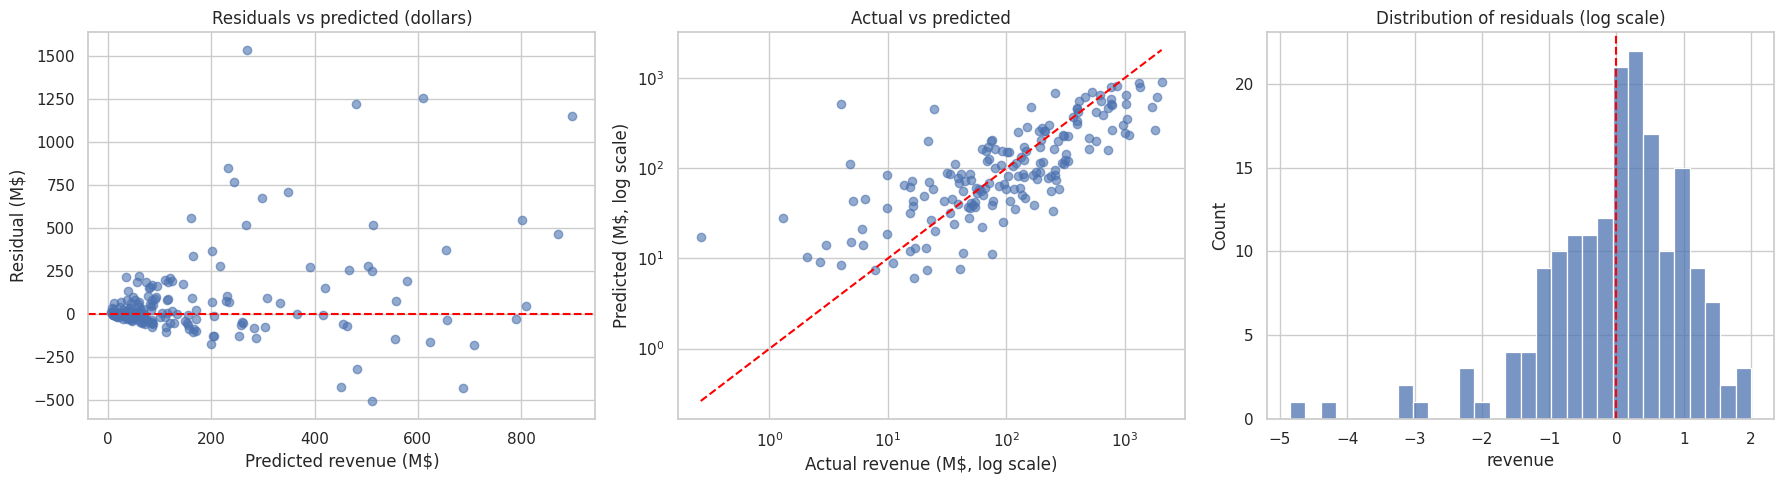

Mean residual (M$): 75.6
Share of movies over-predicted: 43%

Largest under-predictions:


,actual_M,predicted_M,budget_M,residual_M
809,1804.6,268.7,250.0,1535.9
735,1868.2,610.8,150.0,1257.4
646,1698.9,480.6,200.0,1218.3
193,2052.4,899.3,300.0,1153.2
280,1079.0,232.1,55.0,846.9


Largest over-predictions:


,actual_M,predicted_M,budget_M,residual_M
745,4.0,510.3,210.0,-506.3
112,259.2,688.2,150.0,-428.9
739,24.6,450.5,100.0,-425.9
235,160.5,482.5,88.0,-322.0
137,528.0,708.1,125.0,-180.1


In [ ]:
final_model = gb_tuned
pred = final_model.predict(X_test)
resid = y_test - pred
log_resid = np.log1p(y_test) - np.log1p(pred)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].scatter(pred / 1e6, resid / 1e6, alpha=0.6)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted revenue (M$)'); axes[0].set_ylabel('Residual (M$)')
axes[0].set_title('Residuals vs predicted (dollars)')

axes[1].scatter(y_test / 1e6, pred / 1e6, alpha=0.6)
lims = [min(y_test.min(), pred.min()) / 1e6, max(y_test.max(), pred.max()) / 1e6]
axes[1].plot(lims, lims, color='red', linestyle='--')
axes[1].set_xscale('log'); axes[1].set_yscale('log')
axes[1].set_xlabel('Actual revenue (M$, log scale)'); axes[1].set_ylabel('Predicted (M$, log scale)')
axes[1].set_title('Actual vs predicted')

sns.histplot(log_resid, bins=30, ax=axes[2])
axes[2].axvline(0, color='red', linestyle='--')
axes[2].set_title('Distribution of residuals (log scale)')
plt.tight_layout()
plt.show()

print('Mean residual (M$):', round(resid.mean() / 1e6, 1))
print('Share of movies over-predicted: {:.0%}'.format((resid < 0).mean()))
worst = pd.DataFrame({'actual_M': y_test / 1e6, 'predicted_M': pred / 1e6,
                      'budget_M': X_test['budget'] / 1e6, 'residual_M': resid / 1e6})
print('\nLargest under-predictions:')
display(worst.nlargest(5, 'residual_M').round(1))
print('Largest over-predictions:')
display(worst.nsmallest(5, 'residual_M').round(1))



I analyzed the residuals of the final tuned gradient boosting model on the test set, where a residual is the actual revenue minus the predicted revenue. The first plot shows a funnel shape: the errors are small for movies with low predicted revenue and grow larger as the predictions increase, so the model is much less precise for big films. Most of the large residuals are positive and the model never predicts more than about 900 million dollars, although some test movies earned more than 2 billion, which means it compresses the top end. The actual versus predicted plot on a logarithmic scale shows that the model follows the general trend, but the biggest hits lie below the diagonal and are under predicted, while some small films lie above it and are over predicted, which is a pull toward the middle typical of a cautious model. The histogram of the residuals on the logarithmic scale is centered close to 0 but has a long left tail, caused by a few films that earned far less than expected. The mean residual is about 76 million dollars and only 43 percent of the movies are over predicted, so the model under predicts on average. This happens partly because a model trained on the logarithm of revenue predicts something closer to the typical revenue for a film than the average one, and the average in dollars is pulled up by a few huge successes. The largest under predictions are breakout hits that earned between 1.7 and 2.1 billion dollars with budgets of 150 to 300 million, and the largest over predictions include a film with a 210 million budget that earned only 4 million. These patterns show that the model does not capture what makes a film an exceptional success or a flop, such as reviews, word of mouth or marketing, which are not in the data.



### Feature importance and model interpretation

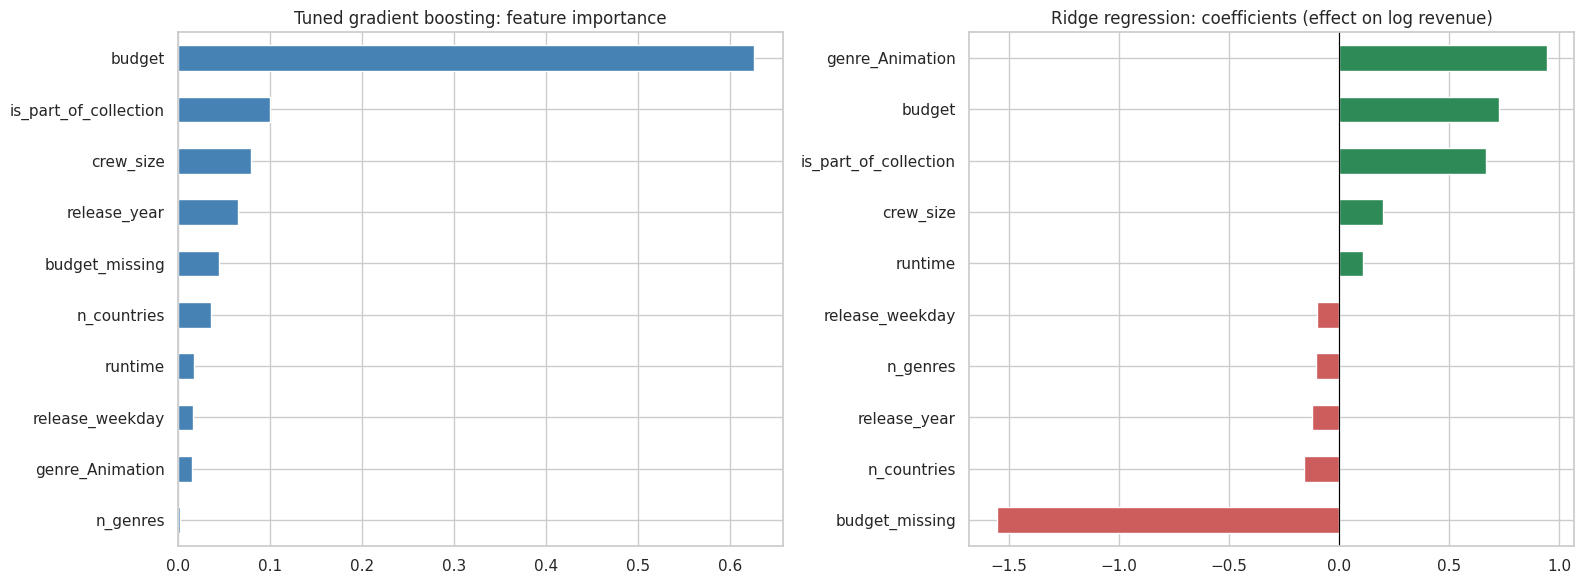

,GB importance,Ridge coefficient
budget,0.627,0.730
is_part_of_collection,0.099,0.669
crew_size,0.080,0.201
release_year,0.065,-0.123
budget_missing,0.044,-1.557
n_countries,0.035,-0.158
runtime,0.017,0.110
release_weekday,0.016,-0.100
genre_Animation,0.015,0.944
n_genres,0.002,-0.107


In [ ]:
gb_fitted = final_model.named_steps['model'].regressor_
ridge_fitted = models['Ridge'].named_steps['model'].regressor_

imp = pd.Series(gb_fitted.feature_importances_, index=final_features).sort_values()
coef = pd.Series(ridge_fitted.coef_, index=final_features).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
imp.plot.barh(ax=axes[0], color='steelblue')
axes[0].set_title('Tuned gradient boosting: feature importance')
coef.plot.barh(ax=axes[1], color=['indianred' if v < 0 else 'seagreen' for v in coef])
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set_title('Ridge regression: coefficients (effect on log revenue)')
plt.tight_layout()
plt.show()

display(pd.DataFrame({'GB importance': imp.sort_values(ascending=False).round(3),
                      'Ridge coefficient': coef.round(3)}).sort_values('GB importance', ascending=False))


I interpreted the models by looking at the feature importance of the tuned gradient boosting model and at the coefficients of ridge regression. In gradient boosting, budget is by far the most important feature, with an importance of 0.63, followed by collection membership at 0.10, crew size at 0.08, release year at 0.07, the missing budget flag at 0.04 and the number of countries at 0.04, while runtime, release weekday, animation and the number of genres contribute very little. The ridge coefficients show the direction of each effect on the logarithm of revenue. Animated films earn about 2.6 times as much as comparable films and films in a collection about twice as much, and a higher budget, a larger crew and a longer runtime are linked to higher revenue. Films with an unknown budget earn about 79 percent less, which agrees with the missingness pattern found during cleaning, since unknown budgets belong mostly to smaller and less documented films. More recent release years and a larger number of production countries are linked to lower revenue, which fits the effect of the pandemic and streaming, and the fact that international co productions usually earn less than large single country productions. Animation has the largest ridge coefficient but a low importance in gradient boosting, because a coefficient measures the effect for each film, while tree importance measures the total contribution across all films, and only a small share of the films are animated. Both models agree that budget and collection membership are the main drivers of revenue.


### Effect of preprocessing and feature selection

In [ ]:

all_feats = list(X_train_prep.columns)
num_cols = ['budget', 'cast_size', 'crew_size', 'runtime'] + other_num

simple_prep = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), num_cols),
    ('binary', 'passthrough', binary_cols),
], verbose_feature_names_out=False).set_output(transform='pandas')

gb_params = {k.replace('model__regressor__', ''): v for k, v in search.best_params_.items()}

def make_variant(reg, cols, log_target=True, prep=None):
    model = (TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1)
             if log_target else reg)
    return Pipeline([('prep', clone(prep if prep is not None else preprocessor)),
                     ('select', ColumnSelector(cols)),
                     ('model', model)]).set_output(transform='pandas')

variants = {
    'Ridge | 10 features | log target | full prep': make_variant(Ridge(alpha=1.0), final_features),
    'Ridge | 33 features | log target | full prep': make_variant(Ridge(alpha=1.0), all_feats),
    'Ridge | 10 features | raw target | full prep': make_variant(Ridge(alpha=1.0), final_features, log_target=False),
    'Ridge | 10 features | log target | scaling only': make_variant(Ridge(alpha=1.0), final_features, prep=simple_prep),
    'Tuned GB | 10 features | log target | full prep': make_variant(GradientBoostingRegressor(random_state=SEED, **gb_params), final_features),
    'Tuned GB | 33 features | log target | full prep': make_variant(GradientBoostingRegressor(random_state=SEED, **gb_params), all_feats),
    'Tuned GB | 10 features | raw target | full prep': make_variant(GradientBoostingRegressor(random_state=SEED, **gb_params), final_features, log_target=False),
}

rows = []
for name, m in variants.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    rows.append({'variant': name,
                 'CV MAE (M$)': -s['test_MAE'].mean() / 1e6,
                 'CV R2': s['test_R2'].mean(),
                 'CV R2 std': s['test_R2'].std(),
                 'CV R2 log': s['test_R2_log'].mean()})
display(pd.DataFrame(rows).set_index('variant').round(3))


,CV MAE (M$),CV R2,CV R2 std,CV R2 log
variant,,,,
Ridge | 10 features | log target | full prep,132.872,0.194,0.427,0.568
Ridge | 33 features | log target | full prep,135.977,0.257,0.238,0.546
Ridge | 10 features | raw target | full prep,148.082,0.466,0.047,-18.420
Ridge | 10 features | log target | scaling only,205.074,-8.828,16.583,0.513
Tuned GB | 10 features | log target | full prep,119.669,0.467,0.108,0.588
Tuned GB | 33 features | log target | full prep,120.272,0.463,0.100,0.579
Tuned GB | 10 features | raw target | full prep,129.914,0.499,0.061,0.254


To measure the effect of preprocessing and feature selection, I compared versions of ridge regression and of the tuned gradient boosting model that differ in one choice at a time, using five fold cross validation on the training data only. Feature selection improved the mean absolute error and the R squared on the logarithmic scale for both models while using only a third of the features, for example from 136 to 133 million dollars for ridge regression and from 120.3 to 119.7 million for gradient boosting, with a smaller effect for gradient boosting because trees already ignore weak features. For ridge regression in dollars the full set of features gave a slightly higher and more stable R squared, so selection mainly helps typical films. Training on the logarithm of revenue instead of on raw dollars gives a trade off: the raw target fits the blockbusters better and raises the R squared in dollars, but it increases the mean absolute error, from 133 to 148 million for ridge regression and from 120 to 130 million for gradient boosting, and it performs very badly on ordinary films, with an R squared of -18.4 on the logarithmic scale for ridge regression because it predicts revenues close to zero or negative for small films. I kept the logarithmic target because it gives the lowest typical error. The transformations and capping are essential for ridge regression: without them its mean absolute error rises from 133 to 205 million dollars and its R squared in dollars falls to -8.8 with a standard deviation of 16.6, because raw budgets in a model of log revenue produce explosive predictions for the films with the largest budgets.

### Limitations

My dataset and approach have several limitations. The movies were chosen as the 100 with the most votes in each year, so the sample is made of well known films and the model may not apply to small or obscure releases. TMDB revenue and budget values are contributed by users and are sometimes missing, rounded or wrong, as the film with a revenue of 7 dollars showed, and revenues are not adjusted for inflation across the ten years. Some streaming releases with small cinema runs may remain in the data even after my rule removed 22 of them. The model only uses information known before release, so it cannot see reviews, word of mouth, marketing spending or competition from other films, which explains why breakout hits are under predicted and expensive flops are over predicted. Because it is trained on the logarithm of revenue, it predicts something closer to the typical revenue of similar films than the average, so it under predicts in dollars on average. With only 876 movies and a test set of 176, the dollar metrics depend strongly on a few blockbusters, and ridge regression in particular can produce very large predictions for films with exceptionally large budgets. Finally, the year 2026 is only partly complete, and films released near the time of collection may not have reached their final revenue.

## Section 14: Advanced Techniques

### SECTION 14A:Yeo-Johnson power transform

,original,previous choice,yeo-johnson,lambda
budget (sqrt before),2.294,0.764,-0.036,0.145
cast_size (log before),3.621,-0.400,0.044,0.121
crew_size (log before),1.710,-0.209,-0.001,0.106
revenue (log before),3.239,-0.647,-0.018,0.106


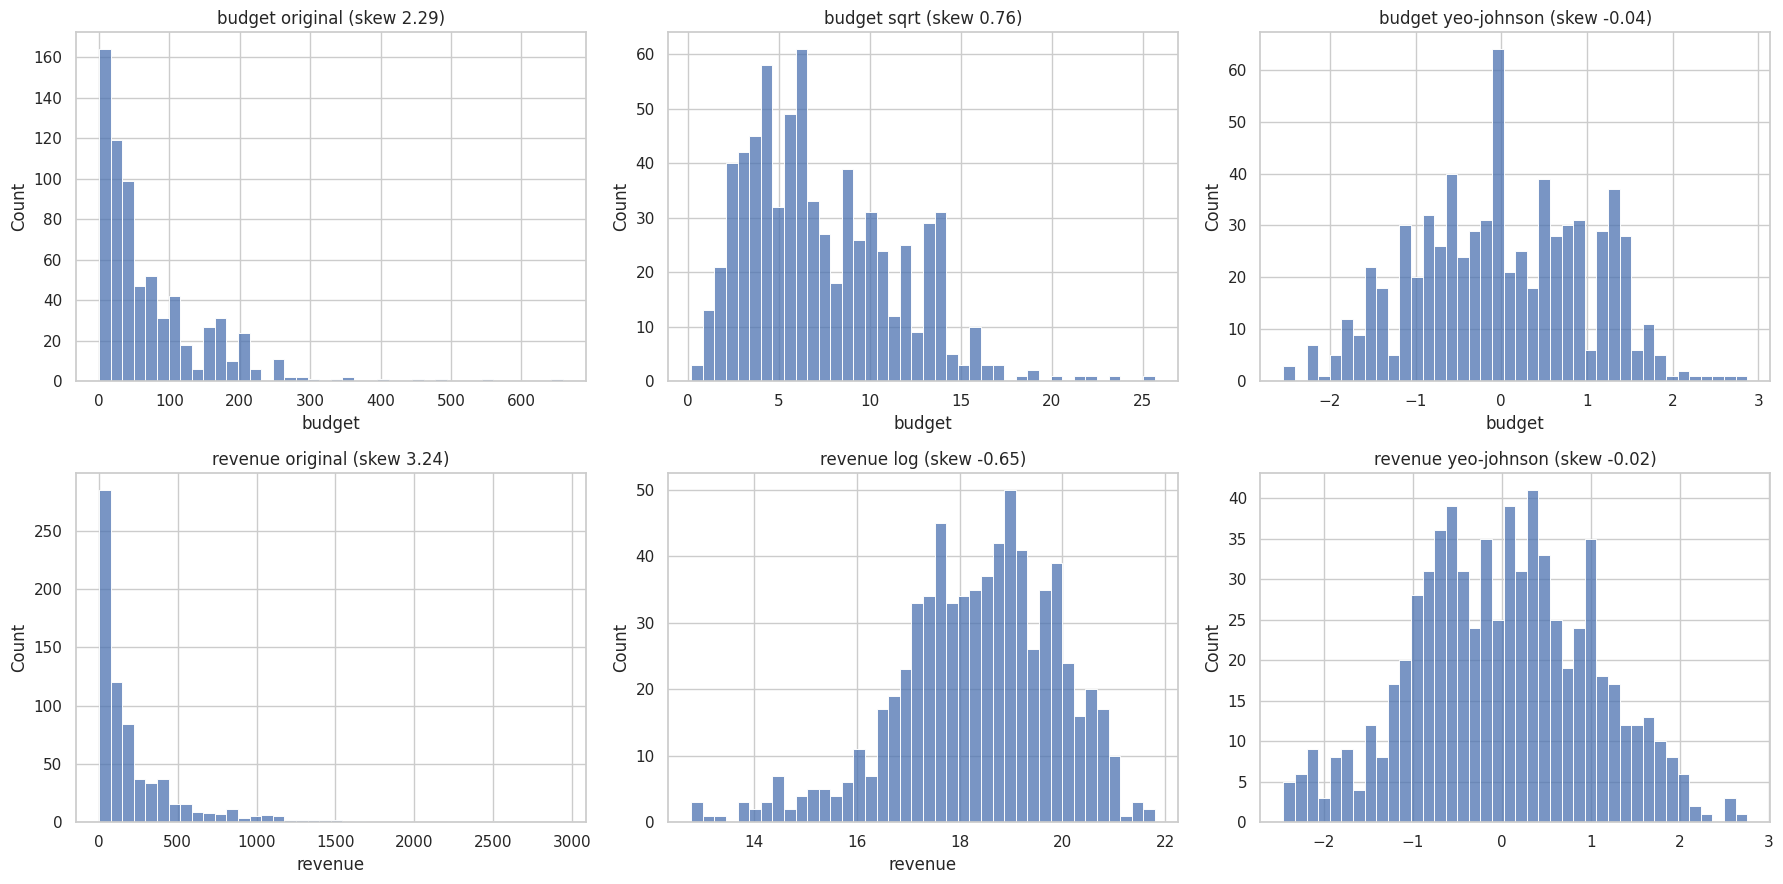

In [ ]:
from sklearn.preprocessing import PowerTransformer

def to_millions(X):
    return X / 1e6

def from_millions(X):
    return X * 1e6

tr = X_train[['budget', 'cast_size', 'crew_size']].copy()
tr['budget'] = tr['budget'].fillna(tr['budget'].median()) / 1e6

pt_x = PowerTransformer(method='yeo-johnson').fit(tr)
yj_x = pd.DataFrame(pt_x.transform(tr), columns=tr.columns)
pt_y = PowerTransformer(method='yeo-johnson').fit(y_train.values.reshape(-1, 1) / 1e6)
yj_y = pd.Series(pt_y.transform(y_train.values.reshape(-1, 1) / 1e6).ravel())

skew_cmp = pd.DataFrame({
    'original': [tr['budget'].skew(), tr['cast_size'].skew(), tr['crew_size'].skew(), y_train.skew()],
    'previous choice': [np.sqrt(tr['budget']).skew(), np.log1p(tr['cast_size']).skew(),
                        np.log1p(tr['crew_size']).skew(), np.log1p(y_train).skew()],
    'yeo-johnson': [yj_x['budget'].skew(), yj_x['cast_size'].skew(), yj_x['crew_size'].skew(), yj_y.skew()],
    'lambda': list(pt_x.lambdas_) + [pt_y.lambdas_[0]],
}, index=['budget (sqrt before)', 'cast_size (log before)', 'crew_size (log before)', 'revenue (log before)'])
display(skew_cmp.round(3))

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for row, (orig, prev, yj, name, prev_name) in enumerate([
        (tr['budget'], np.sqrt(tr['budget']), yj_x['budget'], 'budget', 'sqrt'),
        (y_train / 1e6, np.log1p(y_train), yj_y, 'revenue', 'log')]):
    for col, (data, title) in enumerate([(orig, f'{name} original'),
                                          (prev, f'{name} {prev_name}'),
                                          (yj, f'{name} yeo-johnson')]):
        sns.histplot(data, bins=40, ax=axes[row, col])
        axes[row, col].set_title(f'{title} (skew {pd.Series(data).skew():.2f})')
plt.tight_layout()
plt.show()

I applied the Yeo-Johnson power transform to budget, cast size, crew size and revenue, fitted on the training data only, and compared it with the transformations I chose in the skewness section. Yeo-Johnson searches for the power, called lambda, that makes each variable as close to a bell shape as possible, and unlike Box-Cox it also works with zero values, such as the film with a cast size of 0. I chose it because in the skewness section the logarithm overshot for budget and revenue while the square root was too weak, which suggested that the best power lay somewhere in between. The table confirms this: the lambdas found are between 0.11 and 0.15, which is between a logarithm, with a lambda of 0, and a square root, with a lambda of 0.5, and much closer to the logarithm. Yeo-Johnson brings the skewness of all four variables almost exactly to 0, compared with 0.76 for budget after the square root and -0.65 for revenue after the logarithm. The histograms show the same improvement, as budget and revenue become close to bell shaped and the left tail of the logarithm of revenue disappears. The spike in the middle of the transformed budget comes from the movies whose missing budget was filled with the median. These values are calculated on the training movies only, so they differ slightly from the skewness section, which used the whole dataset.

In [ ]:
def yj_target():
    return Pipeline([('millions', FunctionTransformer(to_millions, inverse_func=from_millions)),
                     ('yj', PowerTransformer(method='yeo-johnson'))])

yj_prep = ColumnTransformer([
    ('budget', Pipeline([('impute', SimpleImputer(strategy='median')),
                         ('millions', FunctionTransformer(to_millions, feature_names_out='one-to-one')),
                         ('yj', PowerTransformer(method='yeo-johnson'))]), ['budget']),
    ('cast_crew', Pipeline([('cap', IQRCapper()),
                            ('yj', PowerTransformer(method='yeo-johnson'))]), ['cast_size', 'crew_size']),
    ('runtime', Pipeline([('cap', IQRCapper()), ('scale', StandardScaler())]), ['runtime']),
    ('other_num', StandardScaler(), other_num),
    ('binary', 'passthrough', binary_cols),
], verbose_feature_names_out=False).set_output(transform='pandas')

def build(reg, prep, target):
    if target == 'log':
        model = TransformedTargetRegressor(regressor=reg, func=np.log1p, inverse_func=np.expm1)
    else:
        model = TransformedTargetRegressor(regressor=reg, transformer=yj_target())
    return Pipeline([('prep', clone(prep)), ('select', ColumnSelector(final_features)),
                     ('model', model)]).set_output(transform='pandas')

gb = lambda: GradientBoostingRegressor(random_state=SEED, **gb_params)
yj_models = {
    'Ridge | before (sqrt/log features, log target)': build(Ridge(alpha=1.0), preprocessor, 'log'),
    'Ridge | YJ features, log target': build(Ridge(alpha=1.0), yj_prep, 'log'),
    'Ridge | YJ features, YJ target': build(Ridge(alpha=1.0), yj_prep, 'yj'),
    'Tuned GB | before (sqrt/log features, log target)': build(gb(), preprocessor, 'log'),
    'Tuned GB | YJ features, YJ target': build(gb(), yj_prep, 'yj'),
}

rows = []
for name, m in yj_models.items():
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    m.fit(X_train, y_train)
    te = metrics(y_test, m.predict(X_test))
    rows.append({'model': name,
                 'CV MAE (M$)': -s['test_MAE'].mean() / 1e6,
                 'CV R2': s['test_R2'].mean(), 'CV R2 std': s['test_R2'].std(),
                 'CV R2 log': s['test_R2_log'].mean(),
                 'test MAE (M$)': te['MAE_M'], 'test RMSE (M$)': te['RMSE_M'], 'test R2': te['R2'],
                 'max train prediction (M$)': m.predict(X_train).max() / 1e6})
yj_table = pd.DataFrame(rows).set_index('model')
display(yj_table.round(3))

,CV MAE (M$),CV R2,CV R2 std,CV R2 log,test MAE (M$),test RMSE (M$),test R2,max train prediction (M$)
model,,,,,,,,
"Ridge | before (sqrt/log features, log target)",132.872,0.194,0.427,0.568,128.613,246.240,0.554,5861.554
"Ridge | YJ features, log target",120.002,0.506,0.096,0.585,130.574,252.271,0.532,2117.729
"Ridge | YJ features, YJ target",116.929,0.512,0.090,0.584,133.963,261.148,0.498,1442.966
"Tuned GB | before (sqrt/log features, log target)",119.669,0.467,0.108,0.588,135.519,270.381,0.462,924.160
"Tuned GB | YJ features, YJ target",118.258,0.493,0.089,0.587,134.729,263.913,0.488,1015.106


I compared the models before and after applying the Yeo-Johnson transform inside the pipeline, using five fold cross validation on the training data and the test set. For ridge regression the change is large. With Yeo-Johnson applied to the features and the target, the cross validated mean absolute error fell from 133 to 117 million dollars, the cross validated R squared rose from 0.19 to 0.51, and its standard deviation across folds fell from 0.43 to 0.09, so the model became far more stable. The reason is visible in the largest prediction on the training data, which fell from 5862 million dollars, the absurd prediction for Jurassic World Dominion, to 1443 million, a realistic value, because Yeo-Johnson compresses very large budgets more strongly than the square root and the linear model no longer extends the budget trend too far. Most of the gain comes from transforming the features, and transforming the target adds a smaller improvement. On the test set ridge regression scores slightly lower than before, with an R squared of 0.50 instead of 0.55, because the films with extreme budgets were all in the training set, so the test set never exposed the old problem, and the five cross validation folds give a fairer picture. For gradient boosting the improvement is small but consistent, with the cross validated mean absolute error falling from 119.7 to 118.3 million and the test R squared rising from 0.46 to 0.49, because tree splits are not changed by transforming the features and only the transformation of the target has an effect. After this technique, ridge regression with Yeo-Johnson has the lowest cross validated error and the highest cross validated R squared of all my models, and it is simple and interpretable, so I select it as my final model.

### Final model after the advanced technique

My final model is ridge regression with the Yeo-Johnson transform applied to budget, cast size, crew size and revenue, trained on the 10 selected features. It replaces the tuned gradient boosting model that I selected in Section 12, because the transform removed the instability that made ridge regression unreliable, and it now has the lowest cross validated mean absolute error, 117 million dollars, and the highest cross validated R squared, 0.51, of all the models I built. On the test set it reaches an R squared of 0.50 and a mean absolute error of 134 million dollars. The residual analysis and the limitations described in Section 12 still apply, because the model still cannot anticipate breakout hits or expensive flops.

In [ ]:
final_model = yj_models['Ridge | YJ features, YJ target']
print('Final model test metrics:', {k: round(float(v), 3) for k, v in metrics(y_test, final_model.predict(X_test)).items()})

Final model test metrics: {'MAE_M': 133.963, 'MSE': 6.8198457221298056e+16, 'RMSE_M': 261.148, 'R2': 0.498}


### SECTION 14B:Missingness pattern analysis

Budget missing vs revenue missing (counts):


revenue_missing,0,1,All
budget_missing,,,
0,867,73,940
1,32,128,160
All,899,201,1100


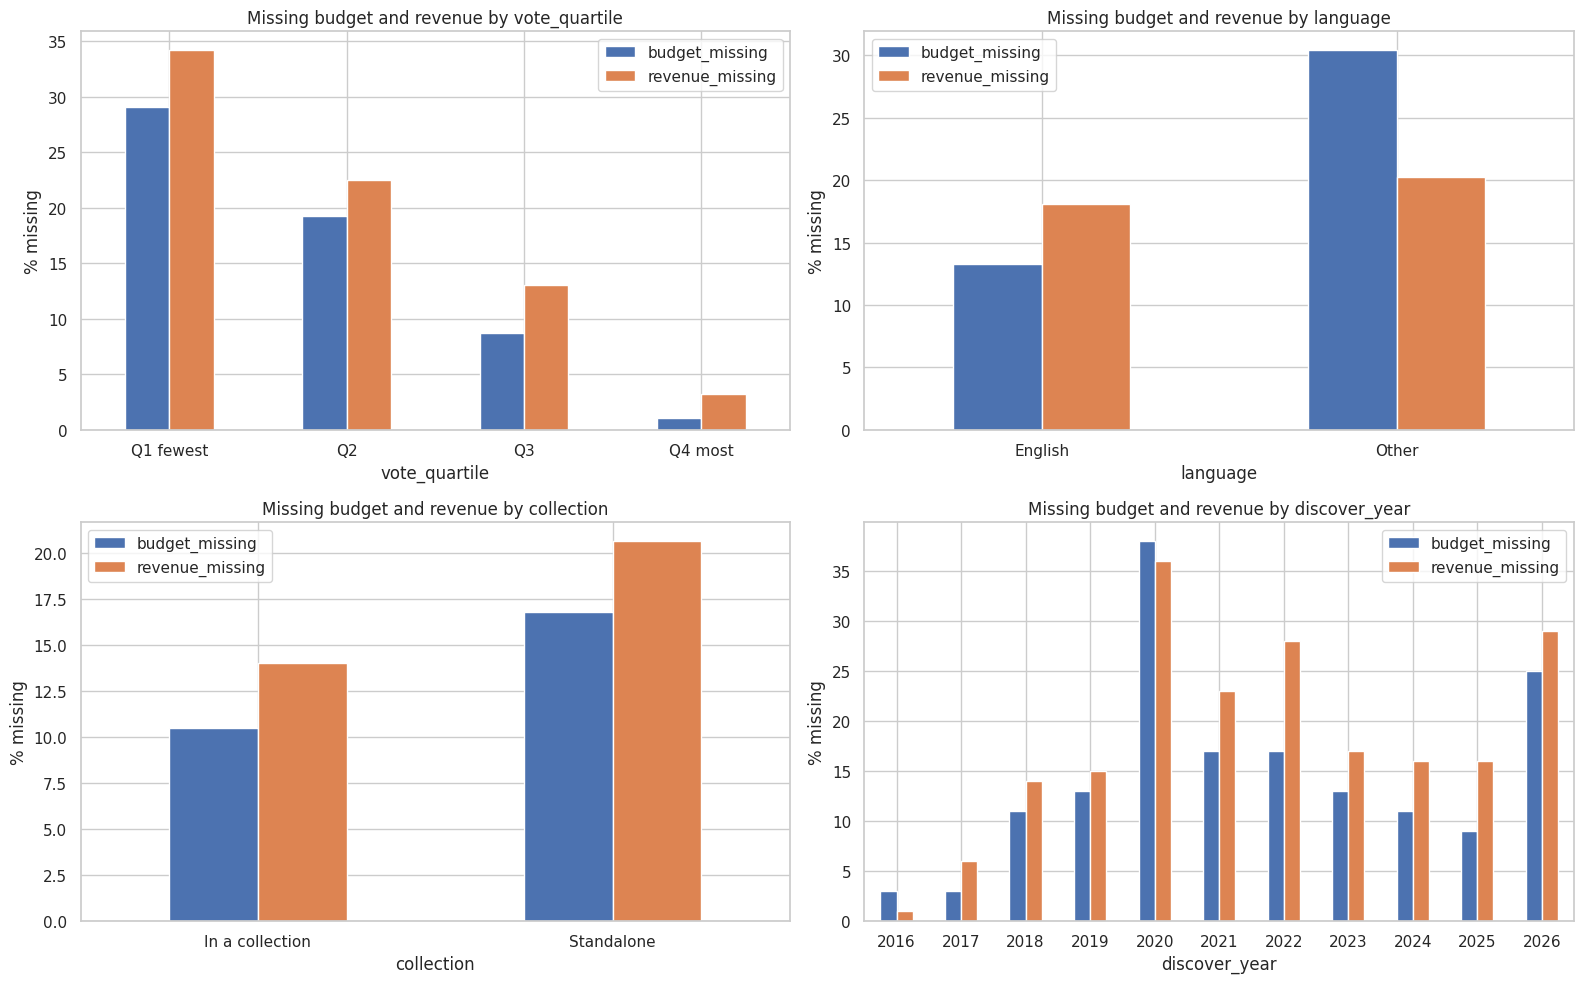

Chi-square tests (is budget missingness independent of the group?):
  vote_quartile   chi2 =   99.29  p = 0.0000
  language        chi2 =   15.82  p = 0.0001
  collection      chi2 =    7.68  p = 0.0056
  discover_year   chi2 =   80.35  p = 0.0000


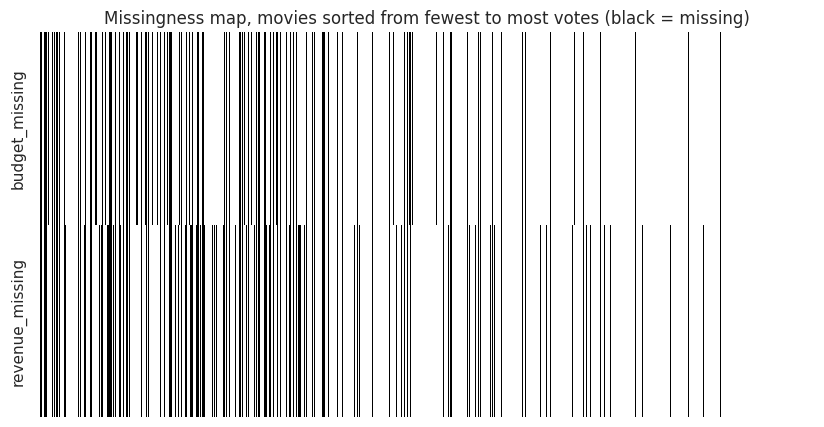

In [ ]:
from scipy.stats import chi2_contingency

miss = raw_df.copy()
miss['budget_missing'] = (miss['budget'] == 0).astype(int)
miss['revenue_missing'] = (miss['revenue'] == 0).astype(int)
miss['language'] = np.where(miss['original_language'] == 'en', 'English', 'Other')
miss['collection'] = np.where(miss['collection_name'].notna(), 'In a collection', 'Standalone')
miss['vote_quartile'] = pd.qcut(miss['vote_count'], 4, labels=['Q1 fewest', 'Q2', 'Q3', 'Q4 most'])

print('Budget missing vs revenue missing (counts):')
display(pd.crosstab(miss['budget_missing'], miss['revenue_missing'], margins=True))

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, g in zip(axes.ravel(), ['vote_quartile', 'language', 'collection', 'discover_year']):
    rates = miss.groupby(g, observed=True)[['budget_missing', 'revenue_missing']].mean() * 100
    rates.plot.bar(ax=ax, rot=0)
    ax.set_ylabel('% missing'); ax.set_title(f'Missing budget and revenue by {g}')
plt.tight_layout()
plt.show()

print('Chi-square tests (is budget missingness independent of the group?):')
for g in ['vote_quartile', 'language', 'collection', 'discover_year']:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(miss[g], miss['budget_missing']))
    print(f'  {g:15s} chi2 = {chi2:7.2f}  p = {p:.4f}')

plt.figure(figsize=(10, 5))
order = miss.sort_values('vote_count').index
sns.heatmap(miss.loc[order, ['budget_missing', 'revenue_missing']].T, cbar=False, cmap='Greys', xticklabels=False)
plt.title('Missingness map, movies sorted from fewest to most votes (black = missing)')
plt.show()

I analyzed the pattern of the missing budgets and revenues in the raw data to test whether they are missing at random. The crosstab shows that they go together: when the budget is missing, the revenue is also missing in 128 of 160 movies, or 80 percent, compared with 73 of 940 movies, or about 8 percent, when the budget is known. The bar charts show that missing values depend strongly on the type of film. Budgets are missing for about 29 percent of the films with the fewest votes but only 1 percent of the films with the most votes, for 30 percent of non English films compared with 13 percent of English films, and more often for standalone films than for films in a collection. By year, very few values are missing in 2016 and 2017, there is a sharp peak in 2020, when cinemas closed and many films were released directly on streaming services, and another rise in 2026, whose films are too recent for complete figures. The chi-square tests confirm that budget missingness is not independent of popularity, language, collection membership or year, since all p values are below 0.05. The missingness map, with the movies sorted from fewest to most votes, shows the missing values concentrated among the less voted films. This means the values are not missing at random but mostly belong to smaller, less popular and less documented films, so filling them with a single median would give these films a budget that is typical of much bigger productions. This justifies keeping the missing budget flag as a feature, and it also means that removing the movies without revenue makes my dataset lean toward more successful films, which is one of the limitations of my model.

In [ ]:
def build_cols(reg, cols):
    return Pipeline([('prep', clone(yj_prep)), ('select', ColumnSelector(cols)),
                     ('model', TransformedTargetRegressor(regressor=reg, transformer=yj_target()))
                     ]).set_output(transform='pandas')

no_flag = [f for f in final_features if f != 'budget_missing']
flag_rows = []
for label, cols in [('without budget_missing flag', no_flag), ('with budget_missing flag', final_features)]:
    m = build_cols(Ridge(alpha=1.0), cols)
    s = cross_validate(m, X_train, y_train, cv=cv, scoring=scoring)
    m.fit(X_train, y_train)
    te = metrics(y_test, m.predict(X_test))
    mask = X_test['budget'].isnull()
    flag_rows.append({'model (final Ridge + YJ)': label,
                      'CV MAE (M$)': -s['test_MAE'].mean() / 1e6, 'CV R2 log': s['test_R2_log'].mean(),
                      'test MAE (M$)': te['MAE_M'], 'test R2': te['R2'],
                      'MAE on missing-budget test films (M$)':
                          mean_absolute_error(y_test[mask], m.predict(X_test)[mask]) / 1e6})
display(pd.DataFrame(flag_rows).set_index('model (final Ridge + YJ)').round(3))

,CV MAE (M$),CV R2 log,test MAE (M$),test R2,MAE on missing-budget test films (M$)
model (final Ridge + YJ),,,,,
without budget_missing flag,118.850,0.547,135.036,0.497,47.746
with budget_missing flag,116.929,0.584,133.963,0.498,6.088


To show the effect of this technique on the model, I trained my final model, ridge regression with the Yeo-Johnson transform, with and without the missing budget flag. With the flag the cross validated mean absolute error fell from 118.9 to 116.9 million dollars and the cross validated R squared on the logarithmic scale rose from 0.547 to 0.584, while the test mean absolute error fell from 135.0 to 134.0 million and the test R squared stayed at about 0.50. The largest improvement is on the logarithmic scale, which gives small films the same weight as big ones, and that is where the flag matters, because the films with missing budgets are mostly small and less popular, as the missingness analysis showed. The dollar metrics change only a little because these films earn little and the dollar errors are dominated by blockbusters. For the four test films with a missing budget, the mean absolute error fell from 47.7 to 6.1 million dollars, because without the flag the model sees the median budget of 41 million and predicts the revenue of a typical mid sized film, while with the flag it can recognize that an unknown budget points to a smaller film. With only four films this is an illustration rather than proof, and the cross validation results are the main evidence. The missingness analysis therefore led to a change in how the data is represented, keeping an indicator of the missing value instead of hiding it behind the median, and this change improved the model.


## Model Training Log


In [11]:
all_models = {
    'Ridge (sqrt/log, log target)': models['Ridge'],
    'Random Forest': models['Random Forest'],
    'Gradient Boosting': models['Gradient Boosting'],
    'Tuned Gradient Boosting': gb_tuned,
    'Ridge + YJ features (log target)': yj_models['Ridge | YJ features, log target'],
    'Tuned Gradient Boosting + YJ': yj_models['Tuned GB | YJ features, YJ target'],
    'FINAL: Ridge + YJ features + YJ target': yj_models['Ridge | YJ features, YJ target'],
}

TRAIN_START = datetime.now()
rows = []
for name, m in all_models.items():
    m.fit(X_train, y_train)
    te = metrics(y_test, m.predict(X_test))
    rows.append({'model': name, 'test MAE (M$)': te['MAE_M'], 'test MSE': '{:.3e}'.format(te['MSE']),
                 'test RMSE (M$)': te['RMSE_M'], 'test R2': te['R2']})
TRAIN_END = datetime.now()
log_table = pd.DataFrame(rows).set_index('model').round(3)

print('=== MODEL TRAINING LOG ===')
print('Team roll numbers   :', ', '.join(ROLL_NUMBERS))
print(f'SEED                : {SEED:04d} (last four digits of the lowest roll number, 25L-0025)')
print('Used as random_state: train-test split, cross-validation folds, random forest,')
print('                      gradient boosting, randomized search, artificial missing values')
print('Training started    :', TRAIN_START.isoformat(timespec='seconds'))
print('Training finished   :', TRAIN_END.isoformat(timespec='seconds'))
print('Training set size   :', X_train.shape[0], 'movies')
print('Test set size       :', X_test.shape[0], 'movies')
print('Features used       :', len(final_features), '->', ', '.join(final_features))
print('Target              : revenue (USD)')
print('\nFinal test metrics for every model:')
display(log_table)

os.makedirs(f'{BASE}/reports', exist_ok=True)
log_table.to_csv(f'{BASE}/reports/model_results.csv')
with open(f'{BASE}/reports/model_training_log.txt', 'w') as f:
    f.write(f"Roll numbers: {ROLL_NUMBERS}\nSEED: {SEED:04d}\n"
            f"Training: {TRAIN_START.isoformat(timespec='seconds')} to {TRAIN_END.isoformat(timespec='seconds')}\n"
            f"Train size: {X_train.shape[0]} | Test size: {X_test.shape[0]}\n\n{log_table.to_string()}\n")

=== MODEL TRAINING LOG ===
Team roll numbers   : 25L-3003, 25L-0025
SEED                : 0025 (last four digits of the lowest roll number, 25L-0025)
Used as random_state: train-test split, cross-validation folds, random forest,
                      gradient boosting, randomized search, artificial missing values
Training started    : 2026-11-27T18:19:03
Training finished   : 2026-11-27T18:19:08
Training set size   : 700 movies
Test set size       : 176 movies
Features used       : 10 -> budget, is_part_of_collection, budget_missing, genre_Animation, crew_size, n_countries, n_genres, release_weekday, release_year, runtime
Target              : revenue (USD)

Final test metrics for every model:


,test MAE (M$),test MSE,test RMSE (M$),test R2
model,,,,
"Ridge (sqrt/log, log target)",128.613,6.063e+16,246.240,0.554
Random Forest,141.473,7.407e+16,272.164,0.455
Gradient Boosting,133.750,6.596e+16,256.831,0.515
Tuned Gradient Boosting,135.519,7.311e+16,270.381,0.462
Ridge + YJ features (log target),130.574,6.364e+16,252.271,0.532
Tuned Gradient Boosting + YJ,134.729,6.965e+16,263.913,0.488
FINAL: Ridge + YJ features + YJ target,133.963,6.820e+16,261.148,0.498


This cell is my model training log. It records my team's roll numbers, the seed, which is 0025, the last four digits of the lowest roll number 25L-0025, and the places where the seed was used as the random state, including the train test split, the cross validation folds, the tree models, the randomized search and the artificial missing values. It also records the date and time of training, on 27 November 2026 from 18:19:03 to 18:19:08, the sizes of the training and test sets, 700 and 176 movies, the 10 features used and the final test metrics of every model I built. The cell trains all seven models itself, and their test results are the same as in the earlier sections, which confirms that the results are reproducible with the seed. The final model, ridge regression with the Yeo-Johnson transform, has a test mean absolute error of about 134 million dollars, a root mean squared error of about 261 million and an R squared of 0.498. The results were also saved to the reports folder on Drive. I will not edit this output, so it can serve as proof that the training and results come from my own work.


